# Prediction Depression in Malawian Children

Note: the data for this project is not made publically available due to a data sensitivity agreement.

*Deniell Nel (s2295525), Aliya Mosha (s2206786) & Kieran Marguerie De Rotrou (s2536961)*

## Setup

In [1]:
# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Models
from sklearn.tree import export_graphviz, DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree
import graphviz
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, recall_score, precision_score, ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve


In [2]:
# Load data  
df = pd.read_csv("unicef_malawi.csv")

# Introduction

This report was commissioned by UNICEF as part of an effort to identify and treat mental health concerns earlier in young people's lives to give them the best chance of reaching their potential. We use data from the 2019-2020 Multiple Indicator Cluster Survey (MICS) for children aged 5-17 years old across different regions in Malawi (MICS6). MICS have been conducted in 125 countries since the mid-1990s and generates data on key indicators on the wellbeing of children to help shape policies for the improvement of their lives. The goal of this report is to build a predictive model for depression among Malawian children aged 5-17, and to identify key risk factors associated with depressive symptoms. The findings are intended to inform social policy and targeted interventions aimed at improving mental health outcomes in Malawi.

We include two models in this report: a pruned decision tree as a baseline, and logistic regression as a final model, chosen for its strong interpretability in a policy context. Our findings suggest that victimisation, mother's happiness, ethnicity, and adult functioning are among the strongest predictors of child depression in this dataset. Overall predictive performance is modest, reflecting the complex nature of depression and the limitations of household survey data.

# Exploratory Data Analysis and Feature Engineering

## Data Overview

The MICS6 dataset contains 13,162 observations containing information about indicators of child wellbeing. This report uses a subset of these indicators across three groups of variables spanning child-level, household-level, and maternal characteristics. Before any EDA is conducted, the dataset it split into a training set (80%) and a test set (20%), stratified by the target variable to preserve class split. All EDA is conducted exclusively on the training set to avoid data leakage. The binary target variable is derived from survey question `FCF26`, which asks how often a child seems depressed or sad. Children who were reported as never seeming sad were classified as not depressed (NO), while those with any episodes of sadness, even just a few times a year, were classified as depressed (YES). These were later encoded as 0 and 1 respectively, for ease of computation during modelling. After removing observations with no response for the target variable, the final dataset contains 13,036 observations, of which 54.7% are classified as depressed and 45.3% as not depressed. Thus, we have a slightly imbalanced dataset.

Child variables capture individual characteristics of the child, including demographics (age, gender, region, area type, ethnicity), educational attainment, labour participation, and types of disciplinary actions they are subject to at home. Household variables capture the living conditions of a child's household including dwelling contruction materials, access to utilities (electricity, water, sanitation infrastructure), access to technology (internet and mobile phone), and asset ownership (dwelling, agricultural land, livestock, bank account). Maternal variables capture characteristics of the child's mother including demographics (age, marital status), education, mental health and wellbeing (happiness, life satisfaction), experience of violence and victimisation, disability status, and substance use. 

## Pre-Processing

The raw UNICEF MICS6 dataset required substantial preprocessing before modelling, spanning child-level, maternal, and household variables. All preprocessing was applied to the full dataset prior to the train/test split to avoid data leakage. Across all variable groups, missing values (`NaN`) and survey non-responses (coded as "NO RESPONSE" or "DK") were unified into a single `NaN` representation before entering the modelling pipeline. This ensures consistent treatment during imputation. For numeric variables, missing values were imputed using the column median, with a binary missingness indicator column automatically appended in order to preserve the information that the original value was absent. All numeric features were subsequently standardised prior to modelling, ensuring fair penalisation across features under L2 regularisation. 

For categorical variables, missing values were imputed with a dedicated "Missing" category prior to one-hot encoding. In particular, for sensitive questions relating to victimisation, domestic violence, and safety, a failure to respond may be informative itself - a respondent unwilling or unable to answer such questions may be signalling distress or a lack of safety in disclosing their experiences. Treating non-response as a distinct category therefore allows the model to potentially exploit this signal, rather than obscuring it by imputing the most common response. For the final logistic regression model, categorical features that displayed a natural ordering were ordinally encoded to preserve this hierarchical structure. These variables were `highest_education_grade`, `mother_highest_education_level`, `mother_literacy`, `mother_happiness`, `mother_life_compared_to_last_year`, `mother_life_expectation_next_year` and `adult_functioning`.

#### Child Variables.

Education level categories "UPPER SECONDARY" and "HIGHER" were collapsed into a single "UPPER SECONDARY AND HIGHER" category given their low individual frequencies. Child discipline was measured across multiple binary sub-questions and combined into three composite variables - `physical punishment` (6 sub-questions), `psychological punishment` (2 sub-questions), and `non-violent discipline` (3 sub-questions), each coded "YES" if any sub-item was selected, and "NO RESPONSE" if all sub-questions were missing. A corresponding proportion score was computed for each composite, representing the fraction of sub-questions selected. This produces a measure of intensity for each of the composite variables which a simple binary variable would otherwise ignore. Rows where the composite was "NO RESPONSE" were set to `NaN` on the proportion score, handled by the same median imputation pipeline as other numeric features. The code for this is shown below. A similar code structure was used for maternal and household variables.

In [3]:
# CHILD VARIABLES DATA CLEANING

df['child_age'] = pd.to_numeric(df['CB3'], errors='coerce')
df['ever_attended_school'] = df['CB4'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)

def clean_cb5a(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif val in ['UPPER SECONDARY', 'HIGHER']:
        return 'UPPER SECONDARY AND HIGHER'
    else:
        return val

df['highest_education_level'] = df['CB5A'].apply(clean_cb5a)
df['highest_education_grade'] = df['CB5B'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) else 'GRADE ' + str(x).split('GRADE ')[-1])
df['current_school_attendance'] = df['CB7'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) else x)
df['has_health_insurance'] = df['CB11'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['area_type'] = df['HH6']
df['region'] = df['HH7']
df['gender'] = df['HL4']
df['wealth_score'] = df['wscore']
df['engaged_in_labour'] = df['CL2'].map({True: 'YES', False: 'NO'})
df['labour_hours_per_week'] = df['CL3'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) else x)
df['engaged_in_household_work'] = df['CL12'].map({True: 'YES', False: 'NO'})
df['household_work_hours_per_week'] = df['CL13'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['physical_punishment_required_raise_children'] = df['FCD5'].apply(lambda x: x if x in ['YES', 'NO'] else 'NO RESPONSE')
df['depression_present'] = df['FCF26'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else ('NO' if x == 'NEVER' else 'YES'))

# Physical punishment: C, F, G, I, J, K
physical_cols = ['FCD2C', 'FCD2F', 'FCD2G', 'FCD2I', 'FCD2J', 'FCD2K']

def categorise_physical(row):
    vals = row.values
    if any(v == 'YES' for v in vals):
        return 'YES'
    elif all(v in ('NO RESPONSE', None) or pd.isna(v) for v in vals):
        return 'NO RESPONSE'
    else:
        return 'NO'
        
df['physical_punishment'] = df[physical_cols].apply(categorise_physical, axis=1)

# Psychological punishment: D, H
psych_cols = ['FCD2D', 'FCD2H']

def categorise_psych(row):
    vals = row.values
    if any(v == 'YES' for v in vals):
        return 'YES'
    elif all(v == 'NO RESPONSE' or pd.isna(v) for v in vals):
        return 'NO RESPONSE'
    else:
        return 'NO'
        
df['psychological_punishment'] = df[psych_cols].apply(categorise_psych, axis=1)

# Non-violent discipline: A, B, E
nonviolent_cols = ['FCD2A', 'FCD2B', 'FCD2E']

def categorise_nonviolent(row):
    vals = row.values
    if any(v == 'YES' for v in vals):
        return 'YES'
    elif all(v == 'NO RESPONSE' or pd.isna(v) for v in vals):
        return 'NO RESPONSE'
    else:
        return 'NO'
        
df['non_violent_discipline'] = df[nonviolent_cols].apply(categorise_nonviolent, axis=1)

#### Maternal Variables.

Mother literacy was recoded from the original three-point scale into "FULLY READ", "PARTIALLY READ", and "CANNOT READ" for clarity. Maternal education was collapsed in the same manner as child education, merging "UPPER SECONDARY" and "HIGHER" into a single category. Victimisation across 7 sub-questions (`VT22A`-`VT22X`) was collapsed into a binary composite coded "YES" if any sub-item was selected, alongside a proportion score reflecting the fraction of sub-questions that had a "YES". Domestic violence attitudes across 5 sub-questions (`DV1A`-`DV1E`) were treated identically. For both variables, rows where all sub-questions were missing were set to "NO RESPONSE" on the composite and `NaN` on the proportion score.

Perceived safety when walking alone at night (`VT20`) and when alone at home at night (`VT21`) were each recoded into three categories: "SAFE" (combining "SAFE" and "VERY SAFE"), "UNSAFE" (combining "UNSAFE" and "VERY UNSAFE"), and a third category capturing those who reported never being in that situation ("NEVER WALK ALONE" and "NEVER ALONE AT HOME" respectively). This three-way distinction was preserved rather than collapsed to binary, as the never-alone group represents a meaningfully different circumstance from those who feel safe or unsafe. Adult functioning across 3 sub-questions (`AF10`-`AF12`) was summarised using a severity-weighted proportion. This assigns 2 points for "A LOT OF DIFFICULTY" and 1 point for "SOME DIFFICULTY" per sub-item, divided by the maximum possible score of 6, yielding a proportion bounded between 0 and 1. A binary composite was also retained indicating the highest difficulty level selected across sub-questions.

In [4]:
# MATERNAL VARIABLES DATA CLEANING

df['mother_age'] = pd.to_numeric(df['WB4'], errors='coerce')
df['mother_ever_attended_school'] = df['WB5'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)

def clean_wb6a(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif val in ['UPPER SECONDARY', 'HIGHER']:
        return 'UPPER SECONDARY AND HIGHER'
    else:
        return val

df['mother_highest_education_level'] = df['WB6A'].apply(clean_wb6a)
df['mother_highest_education_grade'] = df['WB6B'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'DK' else 'GRADE ' + str(x).split('GRADE ')[-1])

def clean_wb14(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif val == 'ABLE TO READ WHOLE SENTENCE':
        return 'FULLY READ'
    elif val == 'ABLE TO READ ONLY PARTS OF SENTENCE':
        return 'PARTIALLY READ'
    else:
        return 'CANNOT READ'

df['mother_literacy'] = df['WB14'].apply(clean_wb14)
df['robbery'] = df['VT1'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x in ['NO RESPONSE', 'DK'] else x)
df['physically_attacked'] = df['VT9'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x in ['NO RESPONSE', 'DK'] else x)

def clean_vt20(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif val in ['SAFE', 'VERY SAFE']:
        return 'SAFE'
    elif val in ['UNSAFE', 'VERY UNSAFE']:
        return 'UNSAFE'
    else:
        return 'NEVER WALK ALONE'

df['safety_walking_night'] = df['VT20'].apply(clean_vt20)

def clean_vt21(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif val in ['SAFE', 'VERY SAFE']:
        return 'SAFE'
    elif val in ['UNSAFE', 'VERY UNSAFE']:
        return 'UNSAFE'
    else:
        return 'NEVER ALONE AT HOME'

df['safety_home_night'] = df['VT21'].apply(clean_vt21)
        
def clean_mstatus(val):
    if pd.isna(val) or val == '9.0':
        return 'NO RESPONSE'
    else:
        return val

df['marital_status'] = df['MSTATUS'].apply(clean_mstatus)
df['husband_age'] = pd.to_numeric(df['MA2'], errors='coerce')
df['husband_multiple_wives'] = df['MA3'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_has_disability'] = df['disability'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) else x)
df['mother_smokes'] = df['TA1'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_drinks'] = df['TA14'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_happiness'] = df['LS1'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_happiness_0to10_scale'] = df['LS2'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_life_compared_to_last_year'] = df['LS3'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['mother_life_expectation_next_year'] = df['LS4'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['num_children_surviving'] = df['CSURV']
df['num_children_deceased'] = df['CDEAD']

# Victimisation
df['VT22A'].value_counts()

VT22_cols = ['VT22A', 'VT22B', 'VT22C', 'VT22D', 'VT22E', 'VT22F', 'VT22X']

def categorise_victimisation(row):
    vals = row.values
    if any(v == 'YES' for v in vals):
        return 'YES'
    elif all(v in ('NO RESPONSE', 'DK') for v in vals):
        return 'NO RESPONSE'
    else:
        return 'NO'

df['victimised'] = df[VT22_cols].apply(categorise_victimisation, axis=1)
df['victimised'].value_counts()

# Adult functioning 
AF_cols = ['AF10', 'AF11', 'AF12']

def categorise_disability(row):
    vals = row.values
    if any(v == 'A LOT OF DIFFICULTY' for v in vals):
        return 'A LOT OF DIFFICULTY'
    elif any(v == 'SOME DIFFICULTY' for v in vals):
        return 'SOME DIFFICULTY'
    else:
        return 'NO DIFFICULTY'

df['adult_functioning'] = df[AF_cols].apply(categorise_disability, axis=1)
df['adult_functioning'].value_counts()

# Attitudes towards domestic violence
DV_cols = ['DV1A', 'DV1B', 'DV1C', 'DV1D', 'DV1E']

def categorise_domestic_violence(row):
    vals = row.values
    if any(v == 'YES' for v in vals):
        return 'YES'
    elif all(v in ('NO RESPONSE', 'DK') for v in vals):
        return 'NO RESPONSE'
    else:
        return 'NO'

df['domestic_violence'] = df[DV_cols].apply(categorise_victimisation, axis=1)

#### Household Variables.

Floor and roof materials were each grouped into the two dominant response categories ("IRON SHEETS / METAL / TIN", "THATCH / PALM LEAF") plus an "OTHER" category to reduce sparsity. Water source was consolidated from a large range of options into five meaningful groups: piped water, tube well/borehole, well, surface water, spring, and other. Toilet type was collapsed into pit latrine, flush, no facility, and other. Water source location was recoded into "OWN PROPERTY" and "ELSEWHERE". Electricity access was recoded into "YES", "NO", and "OTHER" to account for ambiguous response patterns in the raw data.

In [5]:
# HOUSEHOLD VARIABLES DATA CLEANING

df['has_mosquito_net'] = df['TN1']
df['floor_material'] = df['HC4'].apply(lambda x: x if x in ['EARTH / SAND', 'CEMENT'] else 'OTHER')
df['roof_material'] = df['HC5'].apply(lambda x: x if x in ['IRON SHEETS / METAL / TIN', 'THATCH / PALM LEAF'] else 'OTHER')
df['has_electricity'] = df['HC8'].apply(lambda x: 'YES' if str(x).startswith('YES') else ('NO' if x == 'NO' else 'OTHER'))
df['has_computer_or_tablet'] = df['HC11']
df['has_mobile_phone'] = df['HC12']
df['has_internet'] = df['HC13']
df['owns_dwelling'] = df['HC14']
df['owns_agricultural_land'] = df['HC15']
df['owns_livestock'] = df['HC17']
df['has_bank_account'] = df['HC19']

def clean_ws1(val):
    if val == 'TUBE WELL / BOREHOLE':
        return 'TUBE WELL / BOREHOLE'
    elif str(val).startswith('DUG WELL'):
        return 'WELL'
    elif str(val).startswith('PIPED WATER'):
        return 'PIPED WATER'
    elif str(val).startswith('SURFACE WATER'):
        return 'SURFACE WATER'
    elif str(val).startswith('SPRING'):
        return 'SPRING'
    else:
        return 'OTHER'
        
df['water_source'] = df['WS1'].apply(clean_ws1)

def clean_ws3(val):
    if pd.isna(val) or val == 'NO RESPONSE':
        return 'NO RESPONSE'
    elif str(val).startswith('IN OWN'):
        return 'OWN PROPERTY'
    else:
        return 'ELSEWHERE'
        
df['water_source_location'] = df['WS3'].apply(clean_ws3)
df['water_collect_time'] = pd.to_numeric(df['WS4'], errors='coerce')

def clean_ws11(val):
    if str(val).startswith('PIT LATRINE'):
        return 'PIT LATRINE'
    elif str(val).startswith('NO FACILITY'):
        return 'NO FACILITY'
    elif str(val).startswith('FLUSH'):
        return 'FLUSH'
    else:
        return 'OTHER'
        
df['toilet_type'] = df['WS11'].apply(clean_ws11)
df['shared_toilet'] = df['WS15'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)
df['has_soap'] = df['HW5'].apply(lambda x: 'NO RESPONSE' if pd.isna(x) or x == 'NO RESPONSE' else x)

In [6]:
# YES PROPORTION  

# Victimisation proportion (out of 7)
df['victimised_score'] = df[VT22_cols].apply(
    lambda row: (row == 'YES').sum() / len(VT22_cols), axis=1
)
df.loc[df['victimised'] == 'NO RESPONSE', 'victimised_score'] = float('nan')

# Physical punishment proportion (out of 6)
df['physical_punishment_score'] = df[physical_cols].apply(
    lambda row: (row == 'YES').sum() / len(physical_cols), axis=1
)
df.loc[df['physical_punishment'] == 'NO RESPONSE', 'physical_punishment_score'] = float('nan')

# Psychological punishment proportion (out of 2)
df['psychological_punishment_score'] = df[psych_cols].apply(
    lambda row: (row == 'YES').sum() / len(psych_cols), axis=1
)
df.loc[df['psychological_punishment'] == 'NO RESPONSE', 'psychological_punishment_score'] = float('nan')

# Non-violent discipline proportion (out of 3)
df['non_violent_discipline_score'] = df[nonviolent_cols].apply(
    lambda row: (row == 'YES').sum() / len(nonviolent_cols), axis=1
)
df.loc[df['non_violent_discipline'] == 'NO RESPONSE', 'non_violent_discipline_score'] = float('nan')

# Domestic violence attitudes proportion (out of 5)
df['domestic_violence_score'] = df[DV_cols].apply(
    lambda row: (row == 'YES').sum() / len(DV_cols), axis=1
)
df.loc[df['domestic_violence'] == 'NO RESPONSE', 'domestic_violence_score'] = float('nan')

# Adult functioning severity proportion (out of max possible score of 6)
severity_map = {'A LOT OF DIFFICULTY': 2, 'SOME DIFFICULTY': 1}
df['adult_functioning_score'] = df[AF_cols].apply(
    lambda row: sum(severity_map.get(v, 0) for v in row.values) / (2 * len(AF_cols)), axis=1
)

## Exploratory Data Analysis

### Numeric Variables

The box plots below show the numeric variables that display the most noticable differences between depressed and not depressed groups. For `child_age`, depressed children tend to be slightly older compared to non-depressed children (median ~10 vs ~9), though there remains substantial overlap between the two groups. For `wealth_score`, depressed children appear to come from slightly less wealthy households on average, though again the distributions overlap considerably. Looking at `num_children_surviving` and `num_children_deceased`, the mothers of depressed children tend to have more children in general with both these features appearing higher on average compared to mothers of non-depressed children. Children with more siblings may receive less individual parental attention, while children who have experienced the death of a sibling may be at greater risk of depression through grief. For `mother_age` and `husband_age`, the distributions between groups are nearly identical, though depressed children's mothers and fathers tend to be marginally older on average.

`labour_hours_per_week`, `household_work_hours_per_week`, and `water_collect_time`  are all highly right-skewed, with the majority of observations close to zero and distributions dominated by positive outliers. Crucially, the distributions are virtually identical between depressed and non-depressed children, suggesting these variables are unlikely to be strong individual predictors of depression. Overall, none of the numeric variables show strong univariate separation between depressed and non-depressed children. This important early finding suggests that depression is unlikely to be driven by any single numeric indicator in isolation. However, it is possible that a combination of these variables may have a significant impact on the predictive performance of the models.

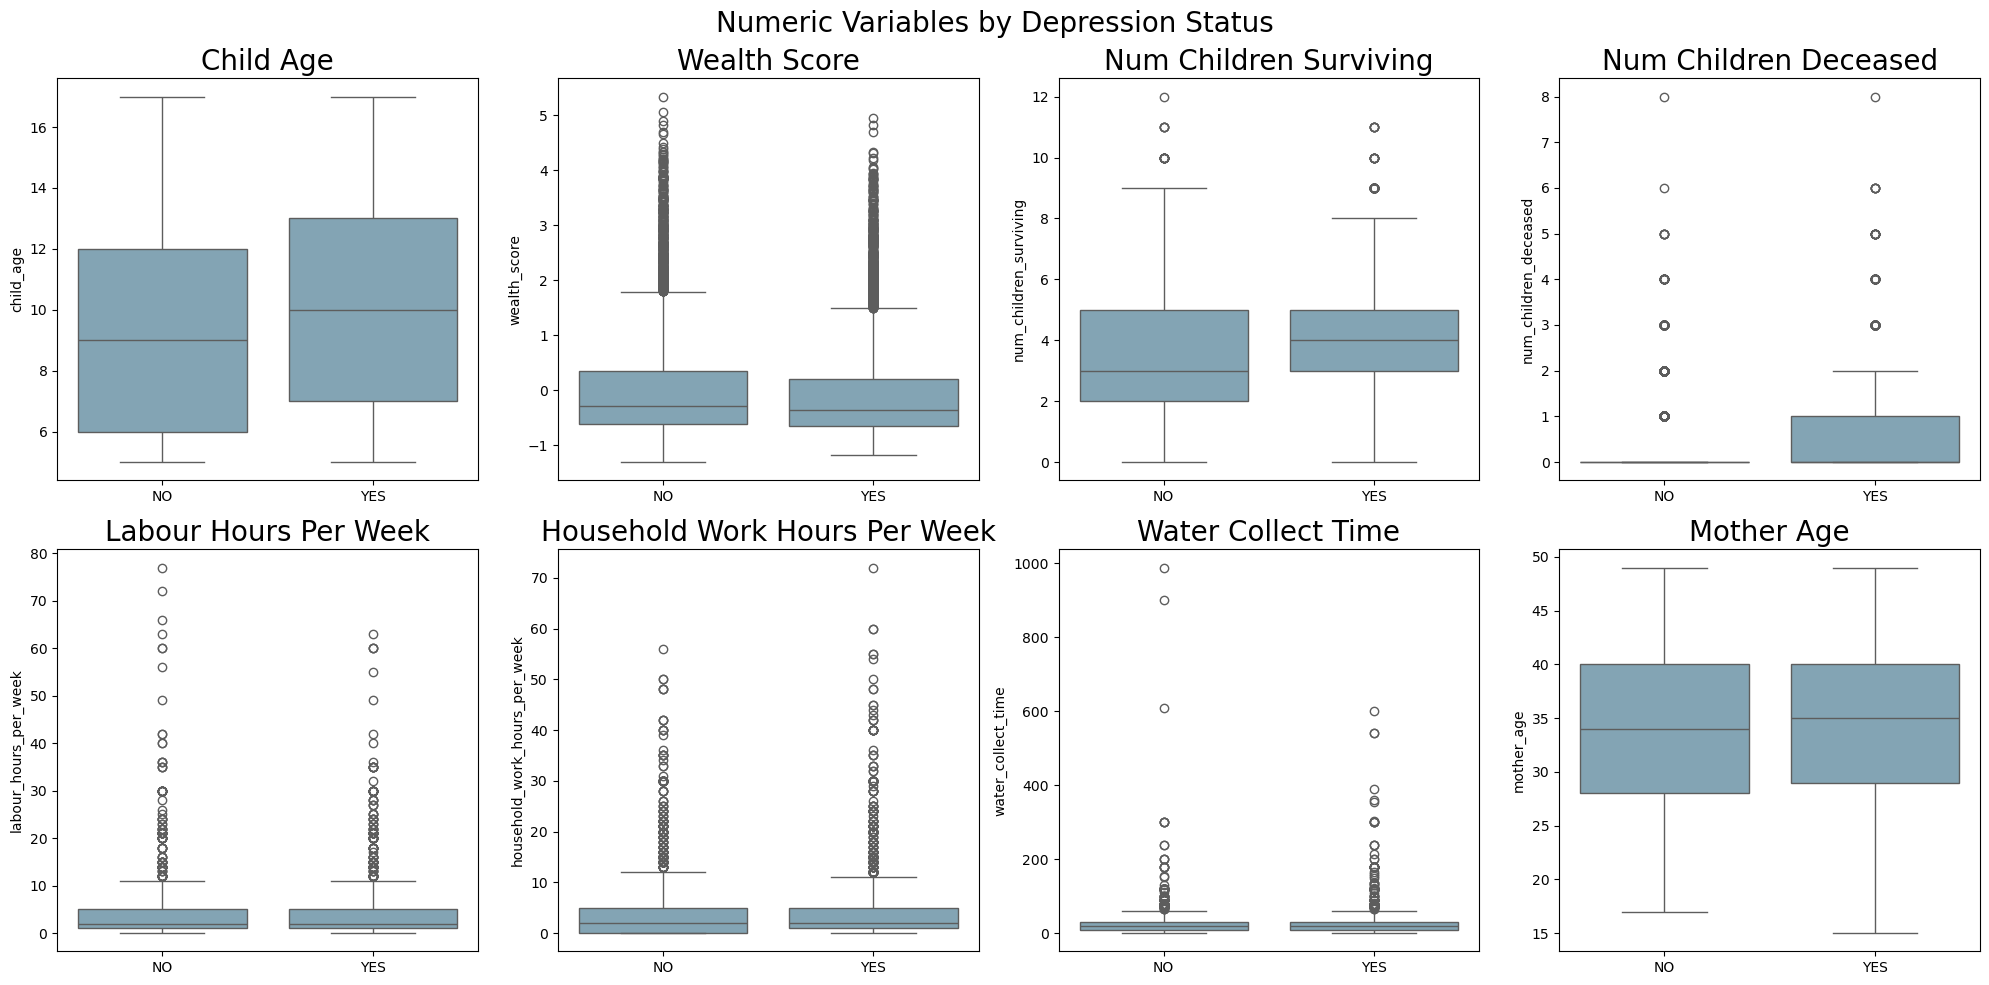

In [7]:
# Train/test split and train_plot setup
target = 'depression_present'
feature_cols = [
    'child_age', 'ever_attended_school', 'highest_education_level',
    'highest_education_grade', 'current_school_attendance', 'has_health_insurance',
    'engaged_in_labour', 'labour_hours_per_week', 'engaged_in_household_work',
    'household_work_hours_per_week', 'physical_punishment_required_raise_children',
    'physical_punishment', 'psychological_punishment', 'non_violent_discipline', 
    'area_type', 'region', 'gender', 'ethnicity', 'wealth_score',
    'has_mosquito_net', 'floor_material', 'roof_material', 'has_electricity',
    'has_computer_or_tablet', 'has_mobile_phone', 'has_internet', 'owns_dwelling',
    'owns_agricultural_land', 'owns_livestock', 'has_bank_account',
    'water_source', 'water_source_location', 'water_collect_time',
    'toilet_type', 'shared_toilet', 'has_soap',
    'mother_age', 'mother_ever_attended_school', 'mother_highest_education_level',
    'mother_literacy', 'robbery', 'physically_attacked', 'safety_walking_night',
    'safety_home_night', 'marital_status', 'husband_age', 'husband_multiple_wives',
    'mother_has_disability', 'mother_smokes', 'mother_drinks', 
    'mother_life_compared_to_last_year', 'mother_life_expectation_next_year',
    'num_children_surviving', 'num_children_deceased',
    'victimised', 'adult_functioning', 'domestic_violence',
    'victimised_score', 'physical_punishment_score', 'psychological_punishment_score',
    'non_violent_discipline_score', 'domestic_violence_score', 'adult_functioning_score',
    'mother_happiness'
]

df_model = df[feature_cols + [target]].copy()
df_model = df_model[df_model[target] != 'NO RESPONSE']
X = df_model[feature_cols]
y = df_model[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_plot = X_train.copy()
train_plot['depression_present'] = y_train

# Key numeric boxplots
important_numeric = ['child_age', 'wealth_score', 
                     'num_children_surviving', 'num_children_deceased',
                     'labour_hours_per_week', 'household_work_hours_per_week',
                     'water_collect_time', 'mother_age']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, col in enumerate(important_numeric):
    plot_data = train_plot[[col, 'depression_present']].copy()
    plot_data[col] = pd.to_numeric(plot_data[col], errors='coerce')
    sns.boxplot(data=plot_data, x='depression_present', y=col,
                ax=axes[i], color='#7BA7BC')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=20)
    axes[i].set_xlabel('', fontsize=18)

fig.suptitle('Numeric Variables by Depression Status', fontsize=20)
plt.tight_layout()
plt.show()

### Composite Score Variables

Several composite variables were derived from multi-question survey items to better capture the intensity of key behaviours and experiences. The construction of these scores is described in detail in the preprocessing section. Briefly, each score aggregates responses across related sub-questions into a single normalised 0-1 scale, where higher values indicate greater intensity or frequency of the underlying behaviour.

Across all six variables, depressed children consistently score higher than non-depressed children, suggesting a  broad pattern of greater adversity among depressed children. The largest relative  difference is observed for `victimised_score` (mean 0.038 vs 0.063), indicating that mothers of depressed children experience notably higher rates of victimisation across the seven sub-questions. `psychological_punishment_score` also shows a meaningful difference (mean 0.539 vs 0.610), suggesting that depressed children are more frequently subjected to psychological punishment such as shouting or threats. Smaller but consistent differences are observed across `physical_punishment_score` (0.231 vs 0.255), `domestic_violence_score` (0.067 vs 0.075), `adult_functioning_score` (0.028 vs 0.041), and `non_violent_discipline_score` (0.636 vs 0.677). While none of these differences are particularly large in absolute terms observed in isolation, the consistent direction across all six scores, with depressed children scoring higher on every adversity measure, is noteworthy. It is important to note that these are univariate comparisons, thus the predictive contribution of these variables may be stronger or weaker when we account for other variables in the model.

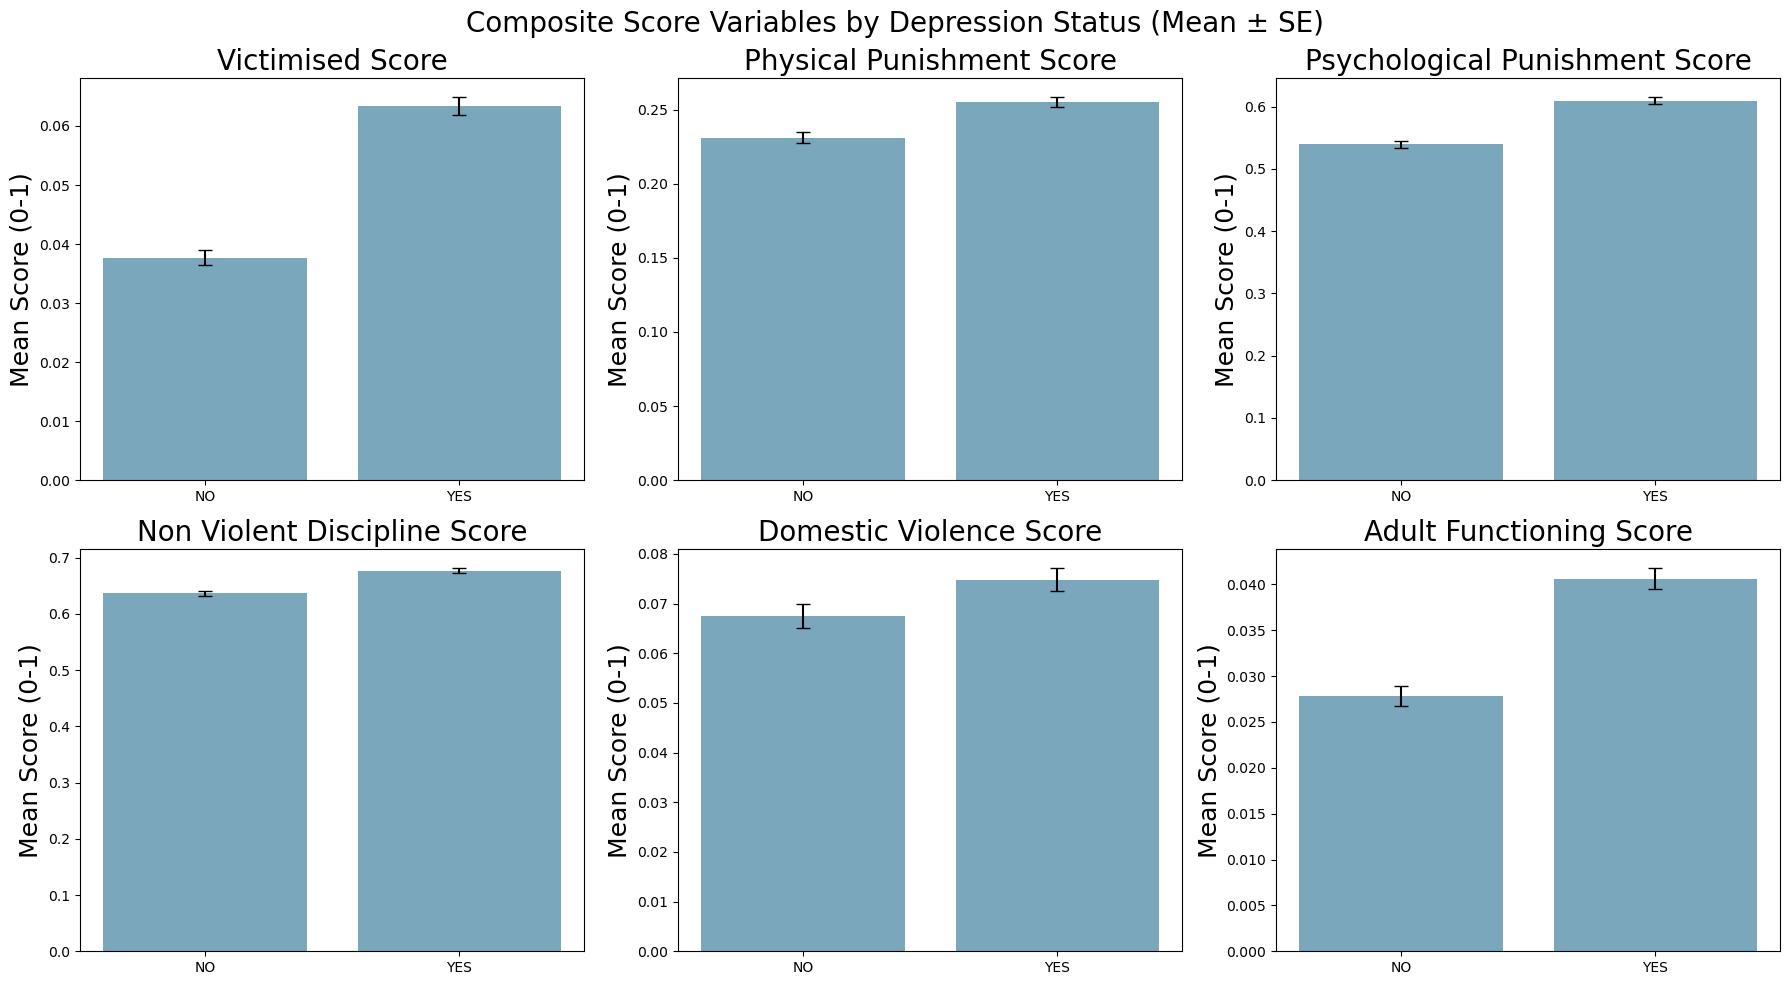

In [8]:
score_cols = [
    'victimised_score', 'physical_punishment_score',
    'psychological_punishment_score', 'non_violent_discipline_score',
    'domestic_violence_score', 'adult_functioning_score'
]

score_check = df[score_cols + ['depression_present']].copy()
score_check = score_check[score_check['depression_present'] != 'NO RESPONSE']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(score_cols):
    stats = score_check.groupby('depression_present')[col].agg(['mean', 'sem'])
    axes[i].bar(stats.index, stats['mean'], yerr=stats['sem'],
                capsize=5, color='#7BA7BC')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=20)
    axes[i].set_xlabel('', fontsize=18)
    axes[i].set_ylabel('Mean Score (0-1)', fontsize=18)

fig.suptitle('Composite Score Variables by Depression Status (Mean ± SE)', fontsize=20)
plt.tight_layout()
plt.show()

### Categorical Variables

#### Child Variables.

The most notable differences in categorical child variables between depressed and not depressed children are shown in the first line of the plot below. Children without health insurance show a notably higher depression rate (0.548) compared to those with insurance (0.411), where health insurance may be a proxy for broader socioeconomic status. Children not currently attending school (0.614) and those engaged in labour (0.602) both show elevated depression rates compared to their counterparts (0.545 and 0.521 respectively), which may reflect either the psychological burden of these circumstances or reverse causality with depression leading to school dropout. Regional and ethnic differences are also present, with the Central region showing the highest depression 
rate (0.597) and the South the lowest (0.508) and with Chewa and Sena children showing the highest depression rates (both 0.598) and Lomwe and Other ethnicity the lowest (0.489 and 0.480 respectively). However, these differences likely reflect regional and socioeconomic factors rather than ethnicity, given the strong overlap between ethnicity and region in [Malawi](https://minorityrights.org/country/malawi/).

#### Household Variables.

Household variables show modest but consistent socioeconomic variation. `toilet_type` shows the widest gap, with children in households with no toilet facility having a depression rate of 0.580 compared to 0.423 for those with a flush toilet. Access to a computer or tablet shows a similar pattern (0.551 vs 0.447). The consistent direction across multiple indicators suggests that household poverty is a meaningful background risk factor for child depression.

#### Maternal Variables.

The maternal variables contain the strongest signals in the dataset. `robbery` shows the largest single gap of any categorical variable. Children whose mothers have experienced robbery have a depression rate of 0.681 compared to 0.539 for those who have not. `mother_happiness` displays a clear gradient from very unhappy (0.670) to very happy (0.480), a gap of nearly 20 percentage points and the most consistent signal in the dataset. `physically_attacked` (0.633 vs 0.542) and `mother_has_disability` (0.631 vs 0.541) also show strong signals, suggesting that maternal vulnerability is closely linked to child depression. `mother_life_expectation_next_year` shows a clear gradient from worse (0.640) to better (0.536), and `marital_status` shows that formerly married mothers have the highest child depression rate (0.610) compared to currently (0.532) and never married (0.520).

Overall, the EDA suggests that maternal mental health, safety, and wellbeing are the most informative predictors of child depression, followed by child-level socioeconomic and educational factors. No single variable shows separation strong enough to predict depression reliably on its own, reinforcing the need for a multivariate modelling approach.

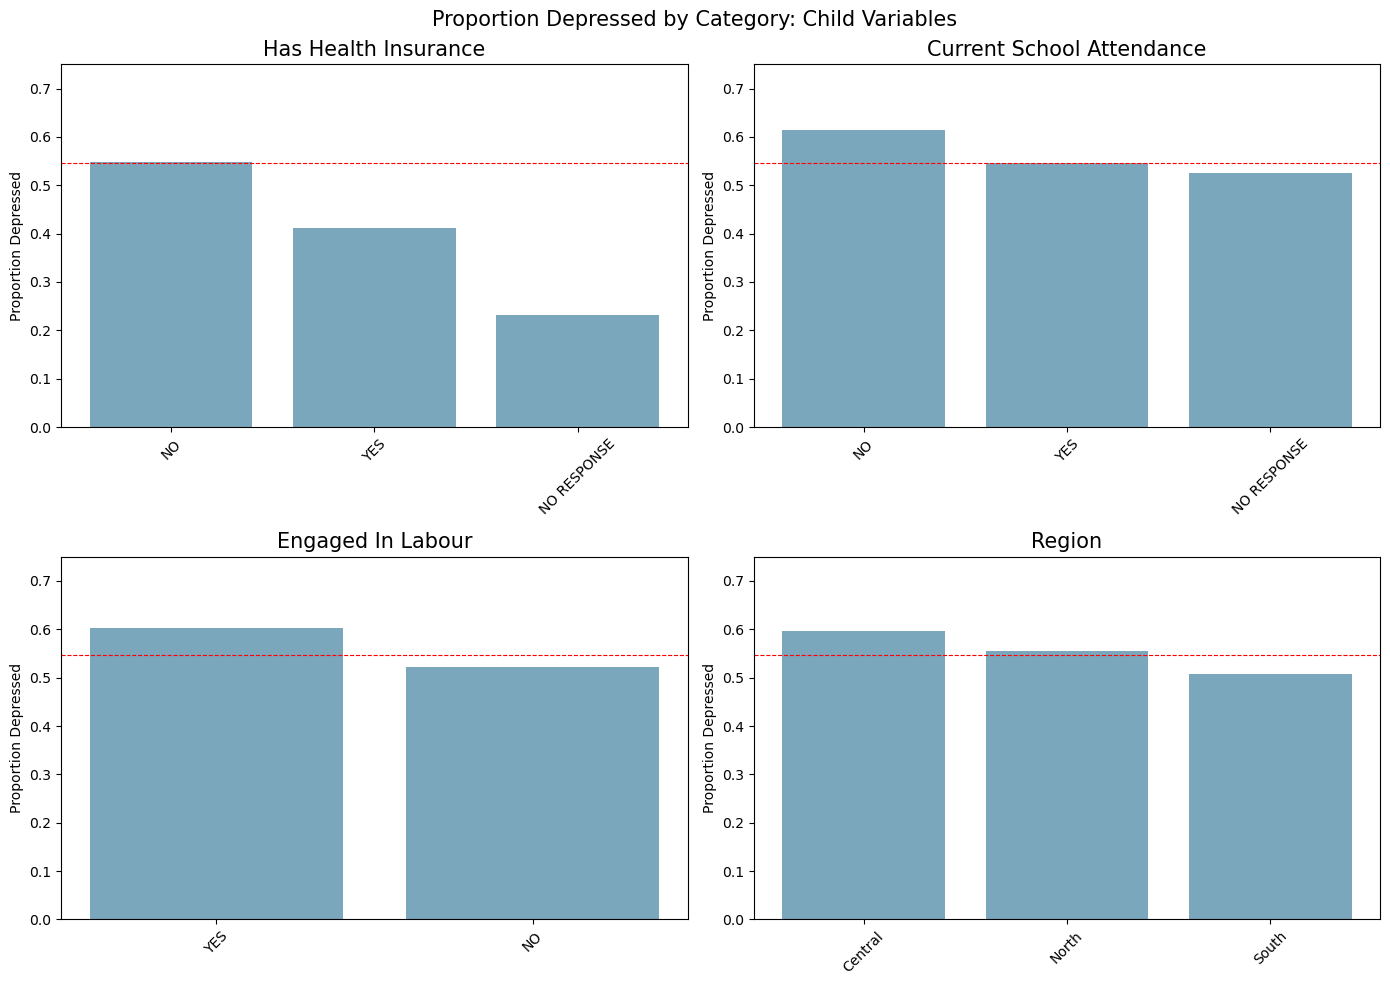

In [9]:
# Child Variables
cols = ['has_health_insurance', 'current_school_attendance', 'engaged_in_labour', 'region']
n_cols = 2
n_rows = 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 10))
axes = np.array(axes).flatten()

for i, col in enumerate(cols):
    prop = (train_plot.groupby(col)['depression_present']
            .apply(lambda x: (x == 'YES').mean())
            .reset_index())
    prop.columns = [col, 'prop_depressed']
    prop = prop.sort_values('prop_depressed', ascending=False)
    axes[i].bar(prop[col], prop['prop_depressed'], color='#7BA7BC')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=15)
    axes[i].set_ylabel('Proportion Depressed')
    axes[i].tick_params(axis='x', rotation=45, labelsize=10)
    axes[i].axhline(y=0.547, color='red', linestyle='--', linewidth=0.8, label='Overall mean')
    axes[i].set_ylim(0, 0.75)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Proportion Depressed by Category: Child Variables', fontsize=15)
plt.tight_layout()
plt.show()

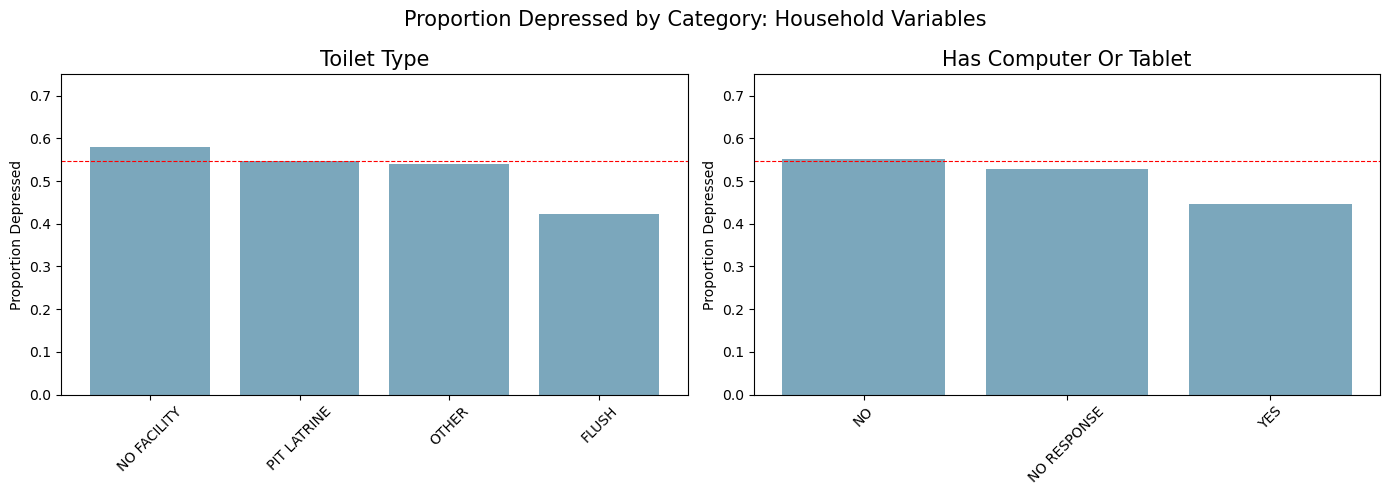

In [10]:
# Household Variables
cols = ['toilet_type', 'has_computer_or_tablet']
n_cols = 2
n_rows = 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5))
axes = np.array(axes).flatten()

for i, col in enumerate(cols):
    prop = (train_plot.groupby(col)['depression_present']
            .apply(lambda x: (x == 'YES').mean())
            .reset_index())
    prop.columns = [col, 'prop_depressed']
    prop = prop.sort_values('prop_depressed', ascending=False)
    axes[i].bar(prop[col], prop['prop_depressed'], color='#7BA7BC')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=15)
    axes[i].set_ylabel('Proportion Depressed')
    axes[i].tick_params(axis='x', rotation=45, labelsize=10)
    axes[i].axhline(y=0.547, color='red', linestyle='--', linewidth=0.8, label='Overall mean')
    axes[i].set_ylim(0, 0.75)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Proportion Depressed by Category: Household Variables', fontsize=15)
plt.tight_layout()
plt.show()

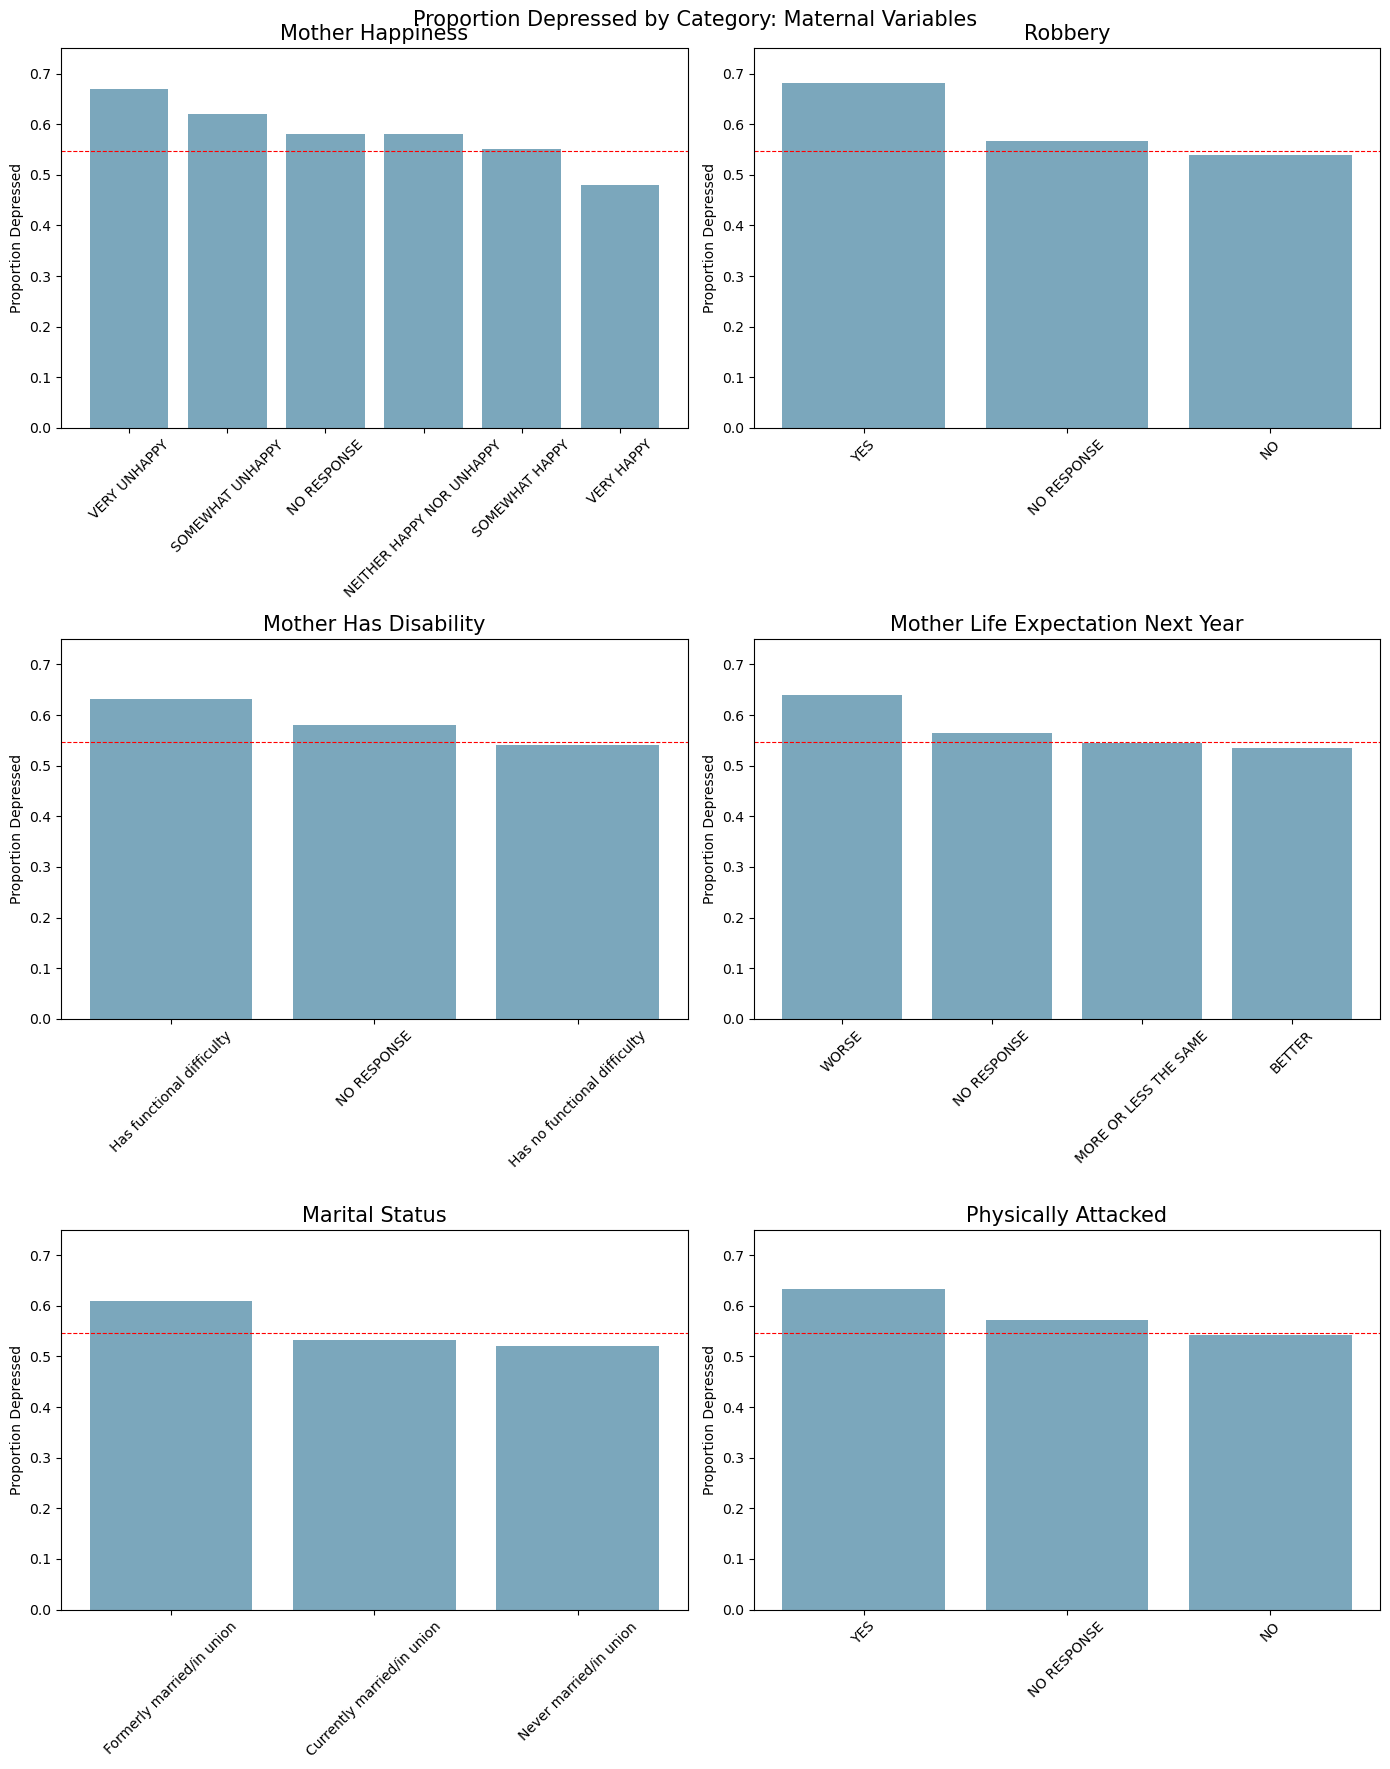

In [11]:
# Maternal Variables
cols = ['mother_happiness', 'robbery', 'mother_has_disability',
        'mother_life_expectation_next_year', 'marital_status', 'physically_attacked']
n_cols = 2
n_rows = 3

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 18))
axes = np.array(axes).flatten()

for i, col in enumerate(cols):
    prop = (train_plot.groupby(col)['depression_present']
            .apply(lambda x: (x == 'YES').mean())
            .reset_index())
    prop.columns = [col, 'prop_depressed']
    prop = prop.sort_values('prop_depressed', ascending=False)
    axes[i].bar(prop[col], prop['prop_depressed'], color='#7BA7BC')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=15)
    axes[i].set_ylabel('Proportion Depressed')
    axes[i].tick_params(axis='x', rotation=45, labelsize=10)
    axes[i].axhline(y=0.547, color='red', linestyle='--', linewidth=0.8, label='Overall mean')
    axes[i].set_ylim(0, 0.75)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Proportion Depressed by Category: Maternal Variables', fontsize=15)
plt.tight_layout()
plt.show()

### Missingness

The graph below shows the proportion of missing values for features that had at least 10% of values missing. Several variables exhibit notably high missingness. `labour_hours_per_week` has the highest missingness at 68%, which is structural - this question is only asked of children who are engaged in labour, so the missing values reflect non-applicability rather than non-response. Similarly, `husband_age` (24%) and `husband_multiple_wives` (23%) are structurally missing as these questions are only asked of currently married mothers. `physical_punishment_required_raise_children` (38%) and `has_soap` (26%) show high non-response rates, likely reflecting question sensitivity. The remaining variables exhibit low missingness with no clear systematic pattern.

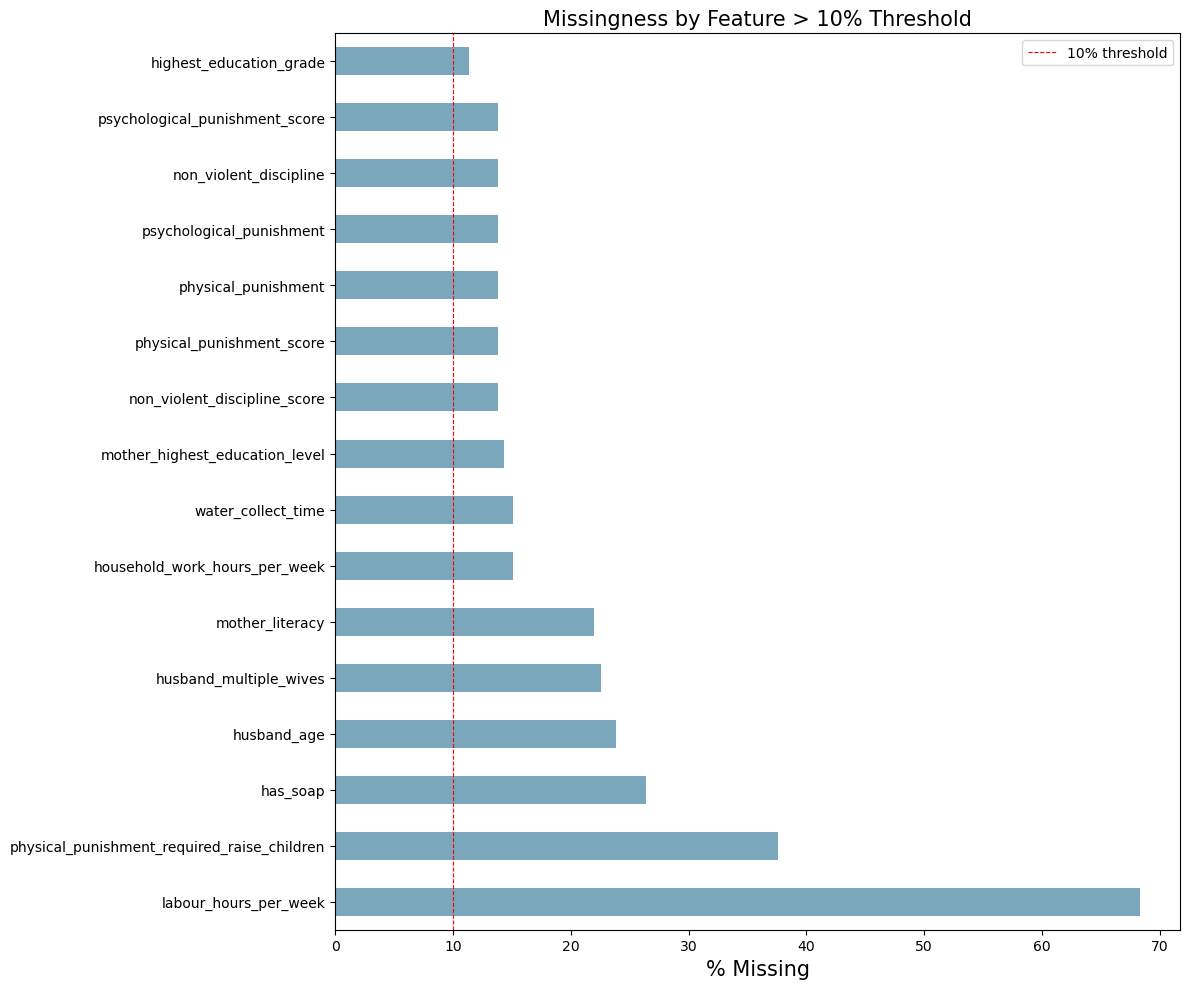

In [12]:
def is_missing(val):
    if pd.isna(val):
        return 1
    if val == 'NO RESPONSE':
        return 1
    return 0

missing = X_train.map(is_missing)
missing_pct = (missing.sum() / len(X_train) * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 10]

plt.figure(figsize=(12, 10))
missing_pct.plot.barh(color='#7BA7BC')
plt.xlabel('% Missing', fontsize=15)
plt.title('Missingness by Feature > 10% Threshold', fontsize=15)
plt.axvline(x=10, color='red', linestyle='--', linewidth=0.8, label='10% threshold')
plt.legend()
plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation analysis for numeric features showed generally low relationships between features, indicating no serious multicollinearity. The strongest correlation is between `mother_age` and `husband_age` (0.79), which is expected and, while potentially redundant, both variables are retained as they may capture different parental influences on child depression. `num_children_surviving` and `num_children_deceased` are moderately correlated with parental age, reflecting that older parents tend to have more children; this relationship is driven by age rather than problematic multicollinearity. Both variables are kept as they may represent different pathways to depression (e.g. reduced parental attention vs. sibling bereavement). `wealth_score` is weakly negatively correlated with `water_collect_time` and `labour_hours_per_week`, aligning with expectations about wealth and resource access. Overall, low correlations suggest features provide largely independent information, so none are removed.

### Model Performance Metrics 

Here we define the metrics that will be used in later sections to evaluate model performance. These metrics are largely based on counts of False Negatives (FN), False Positives (FP), True Negatives (TN) and True Positives (TP), where in our context:

+ **True Positive (TP):** Child has depression and is correctly classified as depressed
+ **True Negative (TN):** Child does not have depression and is correctly classified as not depressed
+ **False Positive (FP):** Child does not have depression but is incorrectly classified as depressed
+ **False Negative (FN):** Child has depression but is incorrectly classified as not depressed

**Accuracy.** This measures the proportion of all observations that are correctly classified: $\text{Accuracy} = \frac{TP + TN}{TP +TN + FP +FN}$. Whilst accuracy is intuitive, it can be a misleading metric for datasets with class imbalance. In the dataset a larger number of children are identified as depressed and so by just predicting depression for most children would improve accuracy but not provide any other meaningful impact. Therefore we look at other performance metrics alongside accuracy.

**Precision.** This measures the proportion of predictions of depression where the child actually has depression: $\text{Precision} = \frac{TP}{TP+ FP}$.

**Recall.** This measures the proportion of observations with depression that are correctly identified: $\text{Recall} = \frac{TP}{TP + FN}$. This is an important and relevant metric as failing to identify a depressed child could have a significant impact on the wellbeing of the child. As such we aim to build a model that not only maximises classification accuracy but also the recall.

**F1-Score.** The F1-Score is a combined measure of recall and precision, and it provides a classification measure that balances both: $\text{F1-Score} = \frac{2 \times \text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$. This will penalise models that perform well only on one of recall and precision. This will be used as our primary performance metric as it is robust to class imbalance and favours neither false negatives nor false positives.

**ROC-AUC.** The ROC curve plots the True Positive Rate (Recall) against the False Positive Rate $\left( \frac{FP}{FP + TN} \right)$ for every possible classification threshold. The area under the curve (AUC) is a value from 0 to 1 with 1.0 a perfect classification: $\text{AUC} = \int_0^1 \text{TPR}(t)d(\text{FPR}(t))$. It measures the model's ability to discriminate between depressed and non-depressed children regardless of any particular threshold.

# Model Fitting and Tuning

## Baseline Model: Decision Tree 

Following preprocessing and feature engineering, a decision tree model was used as an interpretable baseline to predict whether a child is experiencing depression, based on a combination of child, maternal, and household characteristics. The model was implemented within a pipeline that combined preprocessing and estimation, ensuring that all transformations (imputation, scaling, and encoding) were applied consistently within cross-validation.


Before fitting the decision tree, we need to engage in preprocessing to handle missing values in the data and encode categorical variables. For numeric variables, missing values are replaced (imputed) with the median value of that feature. For categorical variables, missing variables are imputed with a placeholder "Missing" category which is then treated as a separate category in the model. This allows us to preserve the information that a value was missing, which may itself be informative in relation to the target variable. All preprocessing steps are wrapped in a single pipeline to prevent data leakage, that is, to ensure that no information from the test set influences the training and model selection process.

In [13]:
pd.set_option('future.no_silent_downcasting', True)
X_train = X_train.replace('NO RESPONSE', np.nan)
X_test = X_test.replace('NO RESPONSE', np.nan)

# define which features are numeric and which are categorical
numeric_features = [
    'child_age', 'labour_hours_per_week', 'household_work_hours_per_week',
    'water_collect_time', 'mother_age', 'husband_age',
    'num_children_surviving', 'num_children_deceased', 'wealth_score',
    'victimised_score', 'physical_punishment_score',
    'psychological_punishment_score', 'non_violent_discipline_score',
    'domestic_violence_score', 'adult_functioning_score', 
]

categorical_features = [col for col in feature_cols if col not in numeric_features]

# numeric pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# categorical pipeline 
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# combine numeric and categorical pipelines into a single preprocessor
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

# fit a full unpruned tree inside a pipeline to get cost complexity pruning path
tree_clf = DecisionTreeClassifier(random_state=42)
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', tree_clf)
])
tree_pipeline.fit(X_train, y_train)

# extract preprocessed training and test data to be used later
X_train_preprocessed = tree_pipeline.named_steps['preprocessor'].transform(X_train)
X_test_preprocessed = tree_pipeline.named_steps['preprocessor'].transform(X_test)

# get full feature names after one-hot encoding 
all_feature_names = (numeric_features +
                     tree_pipeline.named_steps['preprocessor']
                     .named_transformers_['cat']['onehot']
                     .get_feature_names_out(categorical_features).tolist())

# compute the cost complexity pruning path which gives us all possible alpha values
path = tree_clf.cost_complexity_pruning_path(X_train_preprocessed, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

# train one tree for each alpha value so we can compare performance across complexities
clfs = []
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=ccp_alpha)
    clf.fit(X_train_preprocessed, y_train)
    clfs.append(clf)

# record the number of leaves for each tree
node_counts = [clf.get_n_leaves() for clf in clfs]

train_scores = [clf.score(X_train_preprocessed, y_train) for clf in clfs]
test_scores = [clf.score(X_test_preprocessed, y_test) for clf in clfs]

# use 5-fold cross-validation to select the optimal alpha
clf = DecisionTreeClassifier(random_state=42)

gs = GridSearchCV(clf, 
                  param_grid={'ccp_alpha': ccp_alphas}, 
                  cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
gs.fit(X_train_preprocessed, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ccp_alpha': array([0.0000...81432971e-03])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also 

### Selecting the Optimal Tree Complexity

Choosing the right level of complexity is of central importance in fitting decision trees. A tree that is too deep will memorise training data and paint a false picture of accuracy (overfitting). Conversely, a tree that is too shallow will miss important patterns in the data (underfitting). To choose an appropriate level of tree complexity we use cost complexity pruning. We introduce a penalty parameter $\alpha$ that controls the tradeoff between tree complexity and training accuracy by penalising larger trees. A larger $\alpha$ produces a simpler, more pruned tree as it penalises complexity more heavily. To select the optimal value of $\alpha$, we use a stratfied 5-fold cross-validation scheme on the training set: the training data is split into 5 equal parts, and each part is used once as a validation set while the model is trained on the remaining 4. Stratification preserves the proportion of children with and without depression in each fold, reducing the risk of imbalanced splits that could otherwise lead to unstable or misleading validation scores. This is particularly important in this setting, where the outcome variable exhibits mild class imbalance (55% depressed, 45% not depressed). The $\alpha$ that maximises average cross-validation accuracy is then selected as the optimal $\alpha$ value.

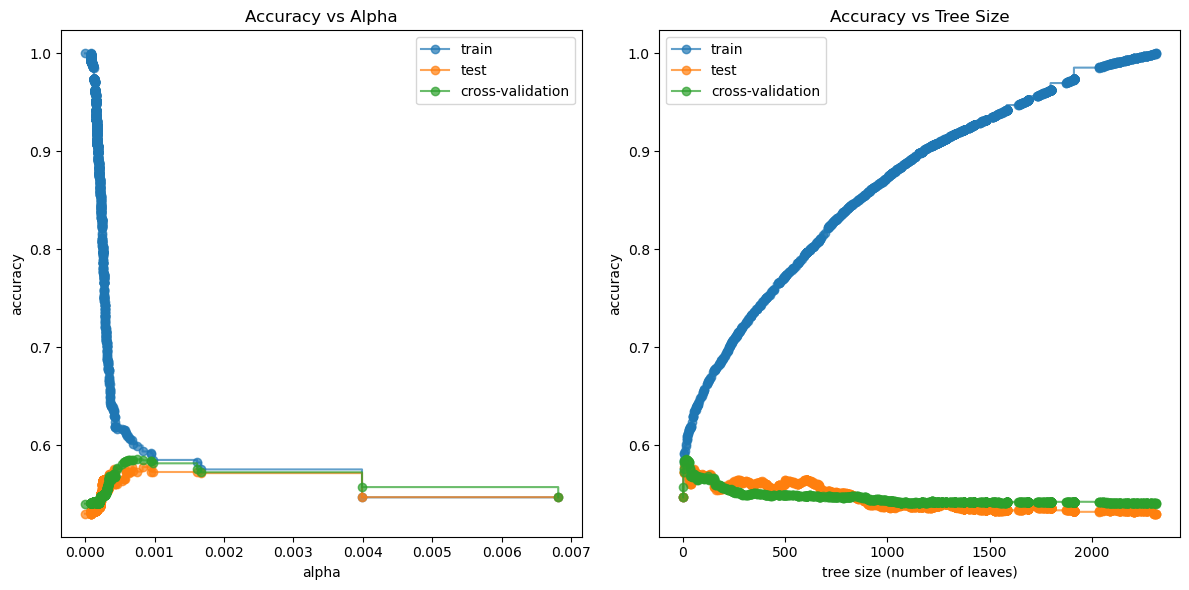

In [14]:
# plot accuracy vs alpha and accuracy vs tree size
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].set_xlabel('alpha')
ax[0].set_ylabel('accuracy')
ax[0].plot(ccp_alphas, train_scores, marker='o', label='train', drawstyle='steps-post', alpha=0.7)
ax[0].plot(ccp_alphas, test_scores, marker='o', label='test', drawstyle='steps-post', alpha=0.7)
ax[0].plot(ccp_alphas, gs.cv_results_['mean_test_score'], marker='o', 
           label='cross-validation', drawstyle='steps-post', alpha=0.7)
ax[0].legend()
ax[0].set_title('Accuracy vs Alpha')
ax[1].set_xlabel('tree size (number of leaves)')
ax[1].set_ylabel('accuracy')
ax[1].plot(node_counts, train_scores, marker='o', label='train', drawstyle='steps-post', alpha=0.7)
ax[1].plot(node_counts, test_scores, marker='o', label='test', drawstyle='steps-post', alpha=0.7)
ax[1].plot(node_counts, gs.cv_results_['mean_test_score'], marker='o', 
           label='cross-validation', drawstyle='steps-post', alpha=0.7)
ax[1].legend()
ax[1].set_title('Accuracy vs Tree Size')
plt.tight_layout()
plt.show()

Using the optimal $\alpha$ = 0.00075 identified by cross-validation, we fit the final pruned decision tree. The tree diagram below shows the full decision logic with each node showing the question being asked, the number of children in that group, and the predicted class. Blue nodes predict depression and orange nodes predict no depression, with darker shading indicating higher confidence. The table below summarises the model's performance on the held-out test set, along with a confusion matrix.

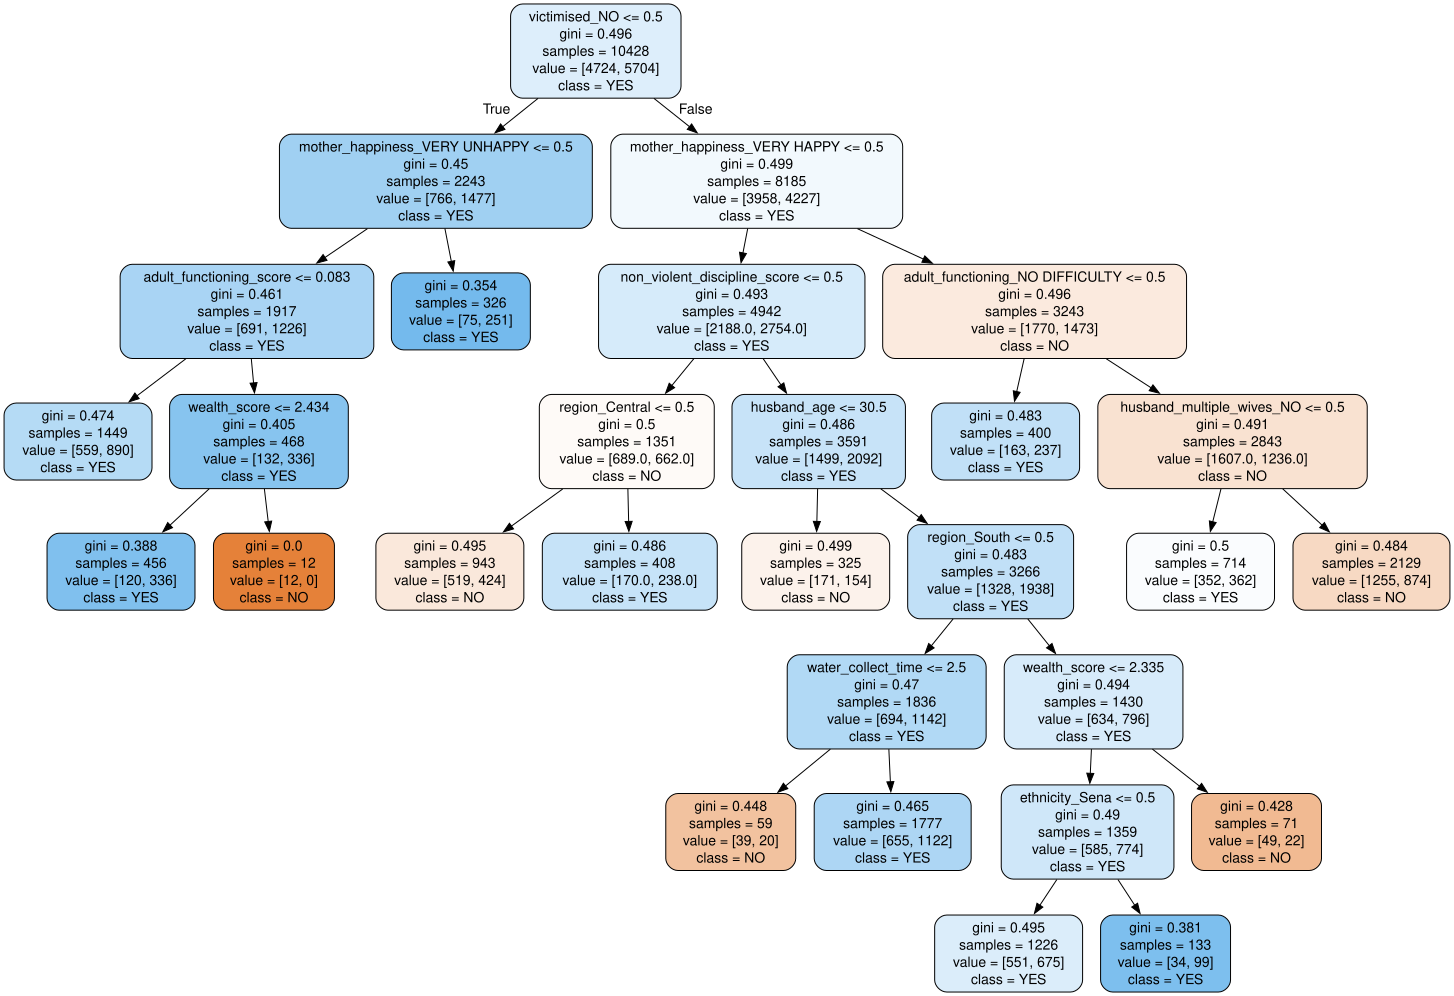

In [15]:
# fit the final pruned tree using the optimal alpha from cross-validation
clf_pruned = DecisionTreeClassifier(ccp_alpha=gs.best_params_['ccp_alpha'], random_state=42)
clf_pruned.fit(X_train_preprocessed, y_train)

# plot the decision tree
tree_data = export_graphviz(
    clf_pruned,
    rounded=True,
    filled=True,
    feature_names=all_feature_names,
    class_names=clf_pruned.classes_.astype(str)
)

graphviz.Source(tree_data)

In [16]:
# predictions
y_pred = clf_pruned.predict(X_test_preprocessed)
y_proba = clf_pruned.predict_proba(X_test_preprocessed)[:, 1]

# ensure numeric labels for AUC
y_test_num = pd.Series(y_test).map({"NO": 0, "YES": 1})

# results table
results_tree = pd.DataFrame({
    "AUC": [roc_auc_score(y_test_num, y_proba)],
    "Accuracy": [accuracy_score(y_test, y_pred)],
    "F1 Score": [f1_score(y_test, y_pred, pos_label="YES")],
    "Recall": [recall_score(y_test, y_pred, pos_label="YES")],
    "Precision": [precision_score(y_test, y_pred, pos_label="YES")],
    "Tree Size (Leaves)": [clf_pruned.get_n_leaves()],
    "Alpha (ccp_alpha)": [gs.best_params_['ccp_alpha']]
}).round(3)

results_tree.index = ["Pruned Decision Tree"]

results_tree

,AUC,Accuracy,F1 Score,Recall,Precision,Tree Size (Leaves),Alpha (ccp_alpha)
Pruned Decision Tree,0.597,0.573,0.646,0.713,0.591,15,0.001


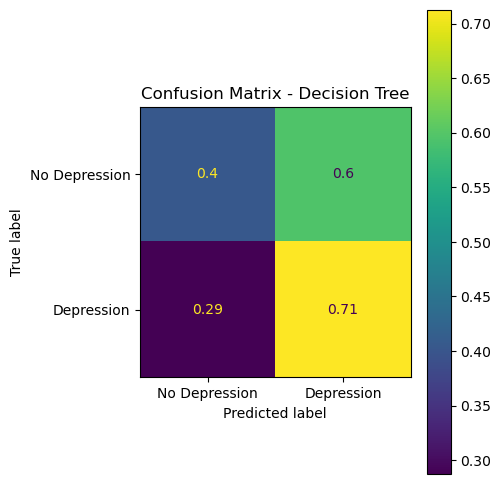

In [17]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_estimator(
    clf_pruned,
    X_test_preprocessed,
    y_test,
    normalize="true",
    display_labels=["No Depression", "Depression"],
    ax=ax
)
ax.set_title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

##  Final Model: Logistic Regression

After fitting a decision tree with modest performance, the final model we chose was a logistic regression model. The basic structure of these types of models is as follows: we assume that the binary categorical response variable (`depression_present`) $y$ is related to the features $\mathbf{x}$ as $$y \sim \text{Bernoulli}\left( \frac{1}{1+\exp(-\mathbf{w}^T \mathbf{x})}\right)$$ where $\mathbf{w}$ are the regression weights or coefficients. Then for every unit increase in a feature $x_d$, the odds of depression are multiplied by a factor of $\exp(w_d)$. To ensure reliable hyperparameter tuning and performance estimation, we again applied a 5-fold cross-validation scheme with stratified folds. This was used to tune the inverse regularisation strength  $C = \left(\frac{1}{\alpha} \right)$ for the L2-penalised logistic regression model. A logarithmically spaced grid of candidate values for $C$ was explored over the range $[10^{-3}, 10^{3}]$, allowing both strong and weak regularisation setups to be assessed. Often with datasets that have a high dimensional feature space, such as MICS6, not all features are necessary and regularisation provides a useful method for highlighting the most important features. The optimal value of the inverse penalty was found to be $C$ = 0.004 (3dp), indicating relatively strong regularisation and suggesting that shrinkage of coefficients was beneficial for generalisation. Other forms of regularisation were applied such as lasso regression which uses an L1 penalty parameter, however this provided no performance improvement.

As outlined in the feature engineering section, ordinal categorical variables (e.g. education, literacy, wellbeing measures) were encoded using ordinal encoding rather than one-hot encoding to preserve ordering and reduce the number of model parameters, improving interpretability. Consequently, `adult_functioning_score` was excluded as it duplicated information captured by the ordinal `adult_functioning` variable. All remaining categorical variables were one-hot encoded, with a reference category chosen (typically the most common group) to allow coefficients to be interpreted as odds ratios relative to a meaningful baseline.

In [18]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    # Tidy up response variable
    
    # Convert target/response to 0/1
    y_train = y_train.map({"NO": 0, "YES": 1})
    y_test = y_test.map({"NO": 0, "YES": 1})
    
    # Replace "NO RESPONSE" with NaN
    X_train = X_train.replace("NO RESPONSE", np.nan)
    X_test = X_test.replace("NO RESPONSE", np.nan)
    
    # Define column groups
    numeric_cols = [
        'child_age', 'labour_hours_per_week', 'household_work_hours_per_week',
        'water_collect_time', 'mother_age', 'husband_age', 
        'num_children_surviving', 'num_children_deceased', 'wealth_score', 
        # Strength scores from collapsed multi-column variables
        'victimised_score',
        'physical_punishment_score',
        'psychological_punishment_score',
        'non_violent_discipline_score',
        'domestic_violence_score'
    ]
    
    ordinal_cols = [
        "highest_education_grade",
        "mother_highest_education_level",
        "mother_literacy",
        "mother_happiness",
        "mother_life_compared_to_last_year",
        "mother_life_expectation_next_year",
        "adult_functioning"
    ]
    
    categorical_cols = [col for col in X_train.columns if col not in numeric_cols and col not in ordinal_cols and col != 'adult_functioning_score']
    
    # Strip any remaining "NO RESPONSE" variants just before encoding
    for col in categorical_cols:
        X_train[col] = X_train[col].replace("NO RESPONSE", np.nan)
        X_test[col] = X_test[col].replace("NO RESPONSE", np.nan)
        
    # Convert NaN to "Missing" manually in training and test sets
    for col in categorical_cols:
        X_train[col] = X_train[col].fillna("Missing")
        X_test[col] = X_test[col].fillna("Missing")
    
    # Numeric pipeline
    num_pipeline = Pipeline([
        # Impute missing numeric values with median + add column to indicate this was a no response/missing
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        
        # Standardise features
        ("scaler", StandardScaler())
    ])
    
    
    # Categorical pipeline
    def reorder_categories_for_baseline(X, categorical_cols, preferred_baselines=None):
        """
        Returns a dict of category lists per column, with the preferred baseline first.
        Falls back to the most frequent category if no preference given.
        """
        categories = []
        for col in categorical_cols:
            counts = X[col].value_counts()
            # Get preferred baseline or fall back to most frequent
            if preferred_baselines and col in preferred_baselines:
                baseline = preferred_baselines[col]
            else:
                # Pick most frequent, but prefer something meaningful over Missing/Other
                for candidate in counts.index:
                    if candidate not in ("Missing", "Other"):
                        baseline = candidate
                        break
                else:
                    baseline = counts.index[0]
            
            # Build ordered list: baseline first, then the rest sorted
            remaining = [c for c in sorted(X[col].unique()) if c != baseline]
            categories.append([baseline] + remaining)
        return categories
    
    preferred_baselines = {
        # Child education 
        "ever_attended_school": "YES",              
        "highest_education_level": "PRIMARY",        
        "highest_education_grade": "GRADE 1",        
        "current_school_attendance": "YES",          
    
        # Child health & resources
        "has_health_insurance": "NO",               
        "has_mosquito_net": "YES",                   
    
        # Child labour 
        "engaged_in_labour": "NO",                  
        "engaged_in_household_work": "YES",       
    
        # Discipline 
        "physical_punishment_required_raise_children": "NO",  
        "physical_punishment": "NO",                
        "psychological_punishment": "NO",      
        "non_violent_discipline": "YES",            
    
        # Household & geography 
        "area_type": "Rural",                       
        "region": "Central",                       
        "gender": "Female",                          
    
        # Ethnicity 
        "ethnicity": "Chewa",                     
    
        # Assets & housing 
        "floor_material": "EARTH / SAND",          
        "roof_material": "THATCH / PALM LEAF",      
        "has_electricity": "NO",                   
        "has_computer_or_tablet": "NO",              
        "has_mobile_phone": "YES",                 
        "has_internet": "NO",                      
        "owns_dwelling": "OWN",                     
        "owns_agricultural_land": "YES",         
        "owns_livestock": "YES",                     
        "has_bank_account": "NO",                  
    
        # Water, sanitation & hygiene 
        "water_source": "TUBE WELL / BOREHOLE",     
        "water_source_location": "ELSEWHERE",        
        "toilet_type": "PIT LATRINE",               
        "shared_toilet": "NO",                      
        "has_soap": "NO",                        
    
        # Safety & victimisation 
        "robbery": "NO",                           
        "physically_attacked": "NO",                
        "safety_walking_night": "SAFE",       
        "safety_home_night": "SAFE",                
        "victimised": "NO",                         
        "domestic_violence": "NO",                 
    
        # Mother characteristics
        "marital_status": "Currently married/in union",    
        "husband_multiple_wives": "NO",                       
        "mother_ever_attended_school": "YES",             
        "mother_smokes": "NO",                              
        "mother_drinks": "NO",                                
    
    }
    
    # Rerorder categories to have the baseline as the first 
    ordered_categories = reorder_categories_for_baseline(
        X_train, 
        categorical_cols, 
        preferred_baselines=preferred_baselines
    )
    
    cat_pipeline = Pipeline([
        ("onehot", OneHotEncoder(
            categories=ordered_categories,   
            drop="first",                   
            handle_unknown="ignore"         
        ))
    ])
    
    
    # Ordinal Pipeline
    
    # highest_education_grade
    grade_order = [
        "Missing",   # imputed NaN/NO RESPONSE
        "GRADE 1", "GRADE 2", "GRADE 3", "GRADE 4",
        "GRADE 5", "GRADE 6", "GRADE 7", "GRADE 8"
    ]
    
    # mother_highest_education_level 
    mother_edu_order = [
        "Missing", "ECE", "PRIMARY", "LOWER SECONDARY",
        "UPPER SECONDARY AND HIGHER", "VOCATIONAL TRAINING"  
    ]
    
    # mother_literacy
    literacy_order = [
        "Missing", "CANNOT READ", "PARTIALLY READ", "FULLY READ"
    ]
    
    # mother_happiness 
    mother_happiness_order = [
        "Missing", "VERY UNHAPPY", "SOMEWHAT UNHAPPY",
        "NEITHER HAPPY NOR UNHAPPY", "SOMEWHAT HAPPY", "VERY HAPPY"
    ]
    
    # mother_life_compared_to_last_year 
    life_last_year_order = [
        "Missing", "WORSENED", "MORE OR LESS THE SAME", "IMPROVED"
    ]
    
    # mother_life_expectation_next_year 
    life_next_year_order = [
        "Missing", "WORSE", "MORE OR LESS THE SAME", "BETTER"
    ]
    
    # adult_functioning - severity scale
    adult_functioning_order = [
        "NO DIFFICULTY", "SOME DIFFICULTY", "A LOT OF DIFFICULTY"
    ]
    
    ordinal_pipeline = Pipeline([
        ("ordinal", OrdinalEncoder(
            categories=[
                grade_order,
                mother_edu_order,
                literacy_order,
                mother_happiness_order,
                life_last_year_order,
                life_next_year_order,
                adult_functioning_order
            ],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])
    
    
    # Combine preprocessing
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, numeric_cols),
        ("ord", ordinal_pipeline, ordinal_cols),   
        ("cat", cat_pipeline, categorical_cols)
    ])
    
    # Full pipeline (preprocessing + model)
    log_pipe = Pipeline([
        ("preprocess", preprocessor),
        
        # Logistic regression with L2 regularisation (strength tuned via CV)
        ("model", LogisticRegression(penalty="l2", 
                                     max_iter=1000,
                                     random_state=42
                                    ))
    ])
    
    # Hyperparameter tuning (C = inverse regularisation strength)
    param_grid = {
        "model__C": np.logspace(-3, 3, 20) # possible C values
    }
    
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    
    log_ridge = GridSearchCV(
        log_pipe,
        param_grid,
        cv=cv,                  # Stratified 5-fold cross-validation
        scoring = ["roc_auc", "accuracy", "f1", "recall", "precision"],
        refit = "accuracy",
        return_train_score = True, 
        n_jobs=-1              
    )
    
    # Fit model 
    log_ridge.fit(X_train, y_train)
    
    # Put CV results in a pandas df 
    cv_results = pd.DataFrame(log_ridge.cv_results_)
    cv_results[[
        "param_model__C",
        "mean_test_accuracy",
        "mean_test_roc_auc",
        "mean_test_f1"
    ]].sort_values("mean_test_accuracy", ascending=False).head()
    
    # Best model + accuracy
    print("Best C:", log_ridge.best_params_["model__C"])
    print("Best CV score (accuracy):", log_ridge.best_score_)

Best C: 0.1623776739188721
Best CV score (accuracy): 0.5972385964670258


### Parameter Tuning Analysis

The F1-score was plotted against $C$ for each cross-validation fold to assess the stability of model performance across different levels of regularisation.  The curves show a consistent trend across folds, with the F1-Score reaching its maximum in the region of $C \approx 0.004$ and performance declining for larger values of $C$ before reaching a plateau. This supports the selection of a relatively small $C$, confirming that stronger regularisation improves the models ability to generalise. The relatively low variability between folds suggests that this result is robust to the choice of training-validation split.


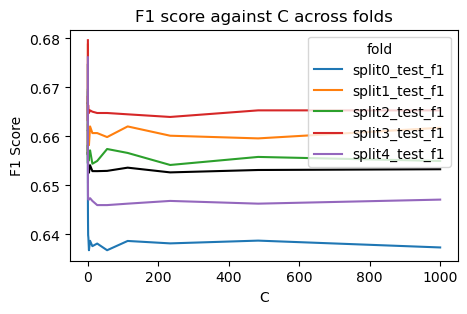

In [19]:
# Extract only mean and split scores
cv_f1 = pd.DataFrame(
    data = log_ridge.cv_results_
).filter(
    # Extract the split#_test_f1 and mean_test_f1 columns
    regex = '(split[0-4]+|mean)_test_f1'
).assign(
    # Add the alphas as a column
    C = np.logspace(-3, 3, 20)
)

# Reshape the data frame for plotting
d = cv_f1.melt(
    id_vars=('C','mean_test_f1'),
    var_name='fold',
    value_name='F1 Score'
)

# Plot the validation scores across folds
plt.figure(figsize=(5,3))
sns.lineplot(x='C', y='F1 Score', color='black', errorbar=None, data = d)  # Plot the mean score in black.
sns.lineplot(x='C', y='F1 Score', hue='fold', data = d) # Plot the curves for each fold in different colors
plt.title("F1 score against C across folds")
plt.show()

### Test Results

The fitted logistic regression model was then applied to the held-out test set, and a summary of the performance metrics can be seen in the table below along with a confusion matrix.

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    
    y_pred = log_ridge.predict(X_test)
    y_proba = log_ridge.predict_proba(X_test)[:, 1]  # probabilities for ROC AUC
    
    results = pd.DataFrame({
        "AUC": [roc_auc_score(y_test, y_proba)],
        "Accuracy": [accuracy_score(y_test, y_pred)],
        "F1 Score": [f1_score(y_test, y_pred)],
        "Recall": [recall_score(y_test, y_pred)],
        "Precision": [precision_score(y_test, y_pred)]
    }).round(3)
    
    results.index = ["Logistic Regression"]

results

,AUC,Accuracy,F1 Score,Recall,Precision
Logistic Regression,0.63,0.598,0.661,0.715,0.614


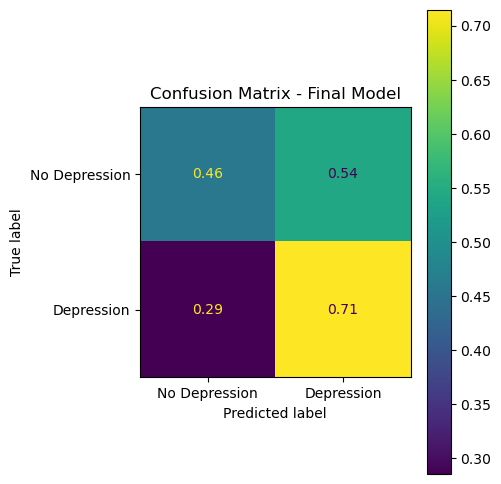

In [21]:
# Confusion Matrix
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_estimator(log_ridge, X_test, y_test, normalize="true",
                                          display_labels=("No Depression", "Depression"),
                                          ax=ax)
    ax.set_title("Confusion Matrix - Final Model")
    plt.tight_layout()
    plt.show()

### Exploring Different Model Choices

A pruned decision tree was used as a baseline due to its simplicity and interpretability, providing a transparent benchmark for comparison. Several more complex models were briefly explored. Ensemble methods (Random Forest, Bagging, and Boosting) produced similar performance to logistic regression (F1 $\approx$ 0.65-0.68), with only marginal gains at the cost of substantially reduced interpretability. While these models can capture more complex patterns, their reliance on many trees makes them difficult to communicate without post-hoc explanation methods.

Support Vector Machines (SVMs) were also tested across linear and non-linear kernels. The best variant (tuned linear kernel) achieved the highest recall (0.819) and slightly higher F1 (0.689), but required careful tuning and showed limited scalability. Performance gains over logistic regression were small and inconsistent. Overall, no alternative model improved F1 score by more than ~0.03 compared to logistic regression, suggesting that increased model complexity does not translate into meaningful predictive gains in this setting.

#### Final Model Choice.

Logistic regression was selected as the final model due to its strong balance of performance and interpretability. It performs comparably to more complex models while providing coefficients that can be directly interpreted as changes in log-odds, making results easily communicable to policy stakeholders. Given the modest performance across all models, the limiting factor appears to be the data rather than model choice.

# Interpretation, Discussion & Conclusions


##  Baseline Model: Pruned Decision Tree
The bar chart below shows which features the decision tree relied on most when making predictions, measured by how much each feature reduced impurity across all splits in the tree. A higher importance score means the feature was more useful for separating depressed from non-depressed children. Only features that appear in at least one split of the pruned tree are shown.

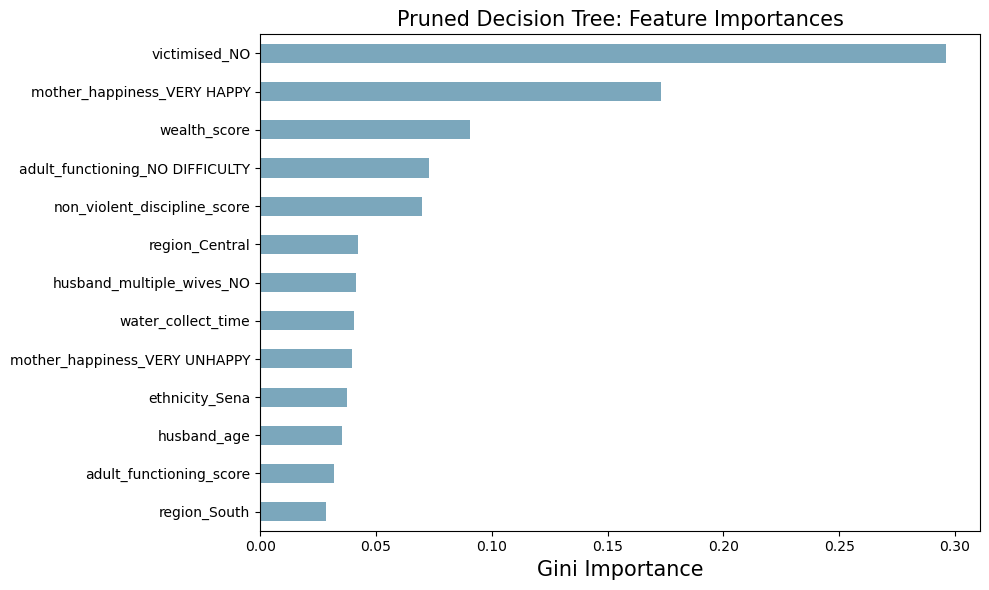

In [22]:
# use all_feature_names since feature_names_out = all_feature_names
feature_names_out = all_feature_names

# extract feature importances - only non-zero values (features used in splits)
importances = pd.Series(
    clf_pruned.feature_importances_, index=feature_names_out
).sort_values(ascending=True)

importances = importances[importances > 0]

# plot as horizontal bar chart
ax = importances.plot.barh(figsize=(10, 6), color='#7BA7BC')
ax.set_title('Pruned Decision Tree: Feature Importances', fontsize=15)
ax.set_xlabel('Gini Importance', fontsize=15)
ax.figure.tight_layout()
plt.show()

## Final Model: Logistic Regression

Here we further analyse the performance of the final chosen model, which had an overall accuracy of 59% and an F1 score of 66%. An alternative specification using `class_weight`="balanced" was also explored to explicitly account for class imbalance. This produced a more symmetric performance profile, with sensitivity (recall for depression) of 59% and specificity of 62%, and an overall accuracy of approximately 60%. However, in this application, false negatives (failing to identify a child experiencing depression) are considered more consequential than false positives, as missed cases may prevent children from receiving appropriate support or intervention. For this reason, the unweighted logistic regression model was retained as the final model. This model achieved a higher sensitivity of 73%, but lower specificity of 43%, with a similar overall accuracy of 59%. While this implies a higher false positive rate (57%), it substantially reduces the risk of failing to detect children who may be experiencing depression. This trade-off reflects a cost-sensitive modelling decision, prioritising recall for the positive class in line with the practical and ethical considerations of the problem context. This trade-off is further highlighted by the ROC curve, which plots the model recall against the false positive rate. Ideally, we would want this curve to hug the top left corner as a higher AUC indicates better model performance.

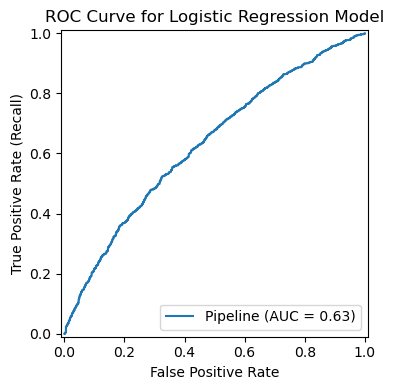

In [23]:
# Plot ROC curve
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    best_pipeline = log_ridge.best_estimator_
    fig, ax = plt.subplots(figsize=(5, 4))
    RocCurveDisplay.from_estimator(best_pipeline, X_test, y_test, ax=ax)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate (Recall)")
    ax.set_title("ROC Curve for Logistic Regression Model")
    plt.tight_layout()
    plt.show()

### Decision Threshold Analysis

By default, logistic regression classifies a child as depressed when the predicted probability of depression exceeds 0.5. However, this threshold is not necessarily the optimal one, particularly in a policy context where the consequences of missing a depressed child (a false negative) may be deemed more problematic than incorrectly flagging one who is not (a false positive). To explore this trade-off explicitly, we searched across all possible classification thresholds and identified two alternatives: one that maximises the F1-score (threshold = 0.401) and one that targets a minimum recall of 80% for the depression class while remaining as precise as possible (threshold = 0.478).

In [24]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
optimal_idx = f1_scores[:-1].argmax()
optimal_threshold = thresholds[optimal_idx]

target_recall = 0.80
# Find the highest threshold that still achieves >= 80% recall
valid_mask = recalls[:-1] >= target_recall
valid_thresholds = thresholds[valid_mask]
recall_threshold = valid_thresholds.max()

In [25]:
y_pred_default   = (y_proba >= 0.50).astype(int)
y_pred_optimised = (y_proba >= optimal_threshold).astype(int)
y_pred_recall = (y_proba >= recall_threshold).astype(int)

print(" Default threshold (0.50) ")
print(classification_report(y_test, y_pred_default, target_names=["No Depression", "Depression"]))

print(f" Optimised threshold ({optimal_threshold:.3f}) ")
print(classification_report(y_test, y_pred_optimised, target_names=["No Depression", "Depression"]))

print(f" Recall-targeted threshold ({recall_threshold:.3f})")
print(classification_report(y_test, y_pred_recall, target_names=["No Depression", "Depression"]))

 Default threshold (0.50) 
               precision    recall  f1-score   support

No Depression       0.57      0.46      0.51      1181
   Depression       0.61      0.71      0.66      1427

     accuracy                           0.60      2608
    macro avg       0.59      0.59      0.58      2608
 weighted avg       0.59      0.60      0.59      2608

 Optimised threshold (0.372) 
               precision    recall  f1-score   support

No Depression       0.68      0.11      0.19      1181
   Depression       0.56      0.96      0.71      1427

     accuracy                           0.57      2608
    macro avg       0.62      0.53      0.45      2608
 weighted avg       0.62      0.57      0.47      2608

 Recall-targeted threshold (0.467)
               precision    recall  f1-score   support

No Depression       0.60      0.36      0.45      1181
   Depression       0.60      0.80      0.69      1427

     accuracy                           0.60      2608
    macro avg       

The recall-targeted threshold represents the most practically useful of the three strategies. It achieves 80% recall for depressed children while keeping precision stable at 0.59, identical to the default, and improving the depression class F1 marginally from 0.66 to 0.68. The cost is a reduction in specificity, with only 0.34 of non-depressed children correctly identified compared to 0.43 at the default threshold, though this is far less severe than the near-total collapse to 0.12 seen under F1 optimisation. The F1-optimised threshold (0.401), despite being selected to maximise F1, actually produces a worse weighted F1 (0.48 vs 0.57) and lower accuracy (0.58 vs 0.59) than the recall-targeted approach, driven by the decrease in performance on the non-depressed class. Taken together, these results suggest that the recall-targeted threshold offers the most sensible balance for this application. The right threshold ultimately remains a policy judgement: if referral resources are limited, even a modest false positive rate among non-depressed children may strain intervention capacity, whereas if initial screening is low-cost, near-complete capture of depressed children may be the priority.

We then visualise the tradeoff in precision and recall for depressed children. The plot shows how precision, recall, and F1-score vary across all possible classification thresholds. Recall (orange) starts near 1.0 at low thresholds and declines steadily as the threshold rises, while precision (blue) follows the opposite trajectory, increasing from around 0.55 as the model becomes more selective. The F1-score (green) remains relatively flat around 0.71 across low thresholds before declining sharply beyond 0.5, indicating that the precision-recall trade-off becomes severe at higher thresholds. The F1-optimised threshold (0.401, red) operates where recall is maximised but at the cost of very low precision, while the recall-targeted threshold (0.478, green) sits closer to the point of F1 decline, achieving 80% recall with a more balanced overall profile. Both thresholds fall below the default 0.5, confirming that explicit threshold lowering is necessary to achieve more targeted case detection for the depression class.

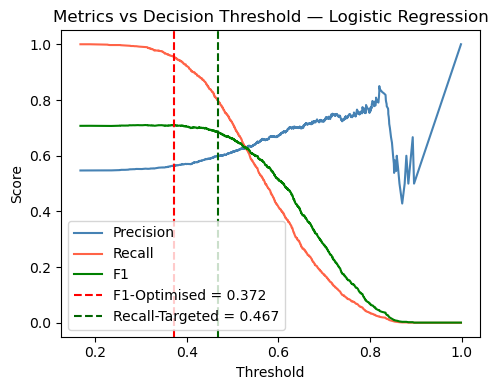

In [26]:
fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(thresholds, precisions[:-1], label='Precision', color='steelblue')
ax.plot(thresholds, recalls[:-1],    label='Recall',    color='tomato')
ax.plot(thresholds, f1_scores[:-1],  label='F1',        color='green')
ax.axvline(x=optimal_threshold, color='red', linestyle='--',
           label=f'F1-Optimised = {optimal_threshold:.3f}')
ax.axvline(x=recall_threshold, color='darkgreen', linestyle='--',
           label=f'Recall-Targeted = {recall_threshold:.3f}')
ax.set_xlabel('Threshold')
ax.set_ylabel('Score')
ax.set_title('Metrics vs Decision Threshold — Logistic Regression')
ax.legend()
plt.tight_layout()
plt.show()

In [27]:
# Get the best fitted pipeline
best_pipe = log_ridge.best_estimator_

# --- Coefficients ---
coefs = best_pipe.named_steps['model'].coef_.flatten()

# --- Feature names ---

# Numeric features (including missing indicators)
num_transformer = best_pipe.named_steps['preprocess'].named_transformers_['num']
num_features = num_transformer.named_steps['imputer'].feature_names_in_.tolist()
num_indicators = []
if hasattr(num_transformer.named_steps['imputer'], 'indicator_'):
    num_indicators = [
        f"{num_features[i]}_missing"
        for i in num_transformer.named_steps['imputer'].indicator_.features_
    ]
numeric_cols_full = num_features + num_indicators

# Ordinal features
ord_transformer = best_pipe.named_steps['preprocess'].named_transformers_['ord']
ordinal_features = ordinal_cols  # The OrdinalEncoder preserves column order
# Names match the order in ordinal_cols
# Optional: can add "_ordinal" suffix if desired
ordinal_features_full = ordinal_features

# Categorical features (after one-hot)
cat_transformer = best_pipe.named_steps['preprocess'].named_transformers_['cat'] \
    .named_steps['onehot']
cat_features = cat_transformer.get_feature_names_out(categorical_cols)

# Combine all features
feature_names = numeric_cols_full + ordinal_features_full + cat_features.tolist()

# --- Build dataframe ---
coef_df = pd.DataFrame({
    "feature": feature_names,
    "coef": coefs
})

# Add odds ratios for interpretation
coef_df["odds_ratio"] = np.exp(coef_df["coef"])

# --- Pretty feature names ---
def clean_feature_name(name):
    # Numeric and ordinal features
    if name in numeric_cols_full or name in ordinal_features_full:
        return name
    # Categorical: var_category
    parts = name.split("_", 1)
    if len(parts) == 2:
        return f"{parts[0]} = {parts[1]}"
    return name

coef_df["pretty_feature"] = coef_df["feature"].apply(clean_feature_name)

highest10_coef_df = coef_df.nlargest(10, 'coef', keep='all')
lowest10_coef_df = coef_df.nsmallest(10, 'coef', keep='all')

largest_coefs20 = [highest10_coef_df, lowest10_coef_df]
influential20_coefs = pd.concat(largest_coefs20)

### Final Model Interpretation & Results 

Model coefficients were examined to identify the most influential predictors of child depression. All associations are interpreted conditional on the other variables being held constant in the model. Maternal functioning emerged as one of the strongest predictors: a one-unit increase in the adult functioning scale ("NO DIFFCULTY" to "A LOT OF DIFFICULTY") was associated with approximately a 17% increase in the odds of child depression (OR = 1.17). Similarly, maternal victimisation was an important factor, with higher victimisation scores associated with increased odds of depression (OR = 1.14), and children of mothers reporting victimisation experiences also more likely to be classified as depressed (OR = 1.13). Exposure to unsafe environments showed a comparable pattern, with children whose mothers reported feeling unsafe walking at night having higher odds of depression (OR = 1.14). Indicators of household conditions also played a role. For example, the presence of soap in the household was associated with slightly higher odds of depression (OR = 1.13), which may reflect underlying reporting or contextual factors rather than a direct causal relationship. Experiences of crime, such as robbery, were also positively associated with depression risk (OR = 1.13).

In contrast, several factors were associated with lower odds of depression. Children living in the Southern region had lower predicted odds compared to the baseline Central region (OR = 0.85). Similarly, belonging to certain ethnic groups, such as Lomwe (OR = 0.87) or other minority ethnicities (OR = 0.86), was associated with reduced odds relative to the reference group (Chewa). Higher maternal happiness was also associated with lower odds of depression (OR = 0.88), reinforcing the importance of maternal well-being.

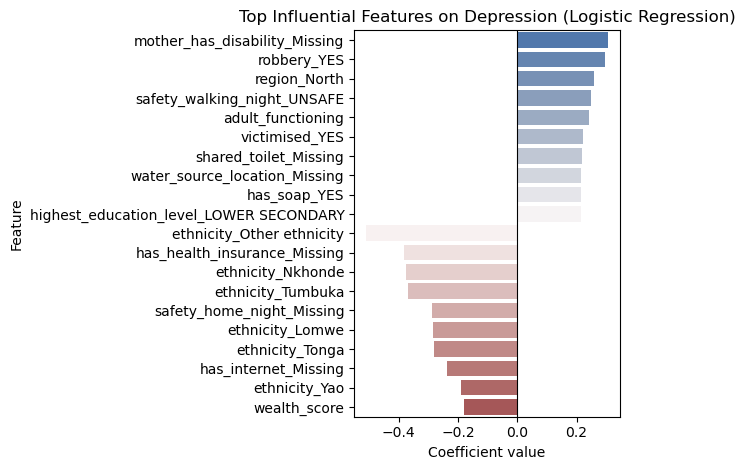

In [28]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    sns.barplot(data = influential20_coefs, x = 'coef', y = 'feature', palette = 'vlag')
    plt.axvline(0, color='black', linewidth=0.8)
    plt.title('Top Influential Features on Depression (Logistic Regression)')
    plt.xlabel('Coefficient value')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

In [29]:
highest5_coef_df = coef_df.nlargest(5, 'coef', keep='all')
lowest5_coef_df = coef_df.nsmallest(5, 'coef', keep='all')

largest_coefs10 = [highest5_coef_df, lowest5_coef_df]
influential10_coefs = pd.concat(largest_coefs10)

influential10_coefs['Feature'] = influential10_coefs['feature']
influential10_coefs['Coefficient'] = influential10_coefs['coef']
influential10_coefs['Odds Ratio'] = influential10_coefs['odds_ratio']

influential10_coefs.reset_index(drop=True, inplace=True)
influential10_coefs[['Feature', 'Coefficient', 'Odds Ratio']]

,Feature,Coefficient,Odds Ratio
0,mother_has_disability_Missing,0.305317,1.357056
1,robbery_YES,0.296505,1.345149
2,region_North,0.259052,1.295702
3,safety_walking_night_UNSAFE,0.247947,1.281392
4,adult_functioning,0.241528,1.273193
5,ethnicity_Other ethnicity,-0.508924,0.601142
6,has_health_insurance_Missing,-0.382450,0.682188
7,ethnicity_Nkhonde,-0.376472,0.686279
8,ethnicity_Tumbuka,-0.368806,0.691559
9,safety_home_night_Missing,-0.288523,0.749370


Overall, the model highlights the importance of maternal well-being, exposure to violence, and perceived safety, alongside demographic context, in predicting child depression. However, because the model uses L2-regularised logistic regression, coefficients are shrunk toward zero and should be interpreted as relative indicators of importance rather than precise causal effects. Additionally, as a linear model, logistic regression cannot capture complex interactions or non-linear relationships. Despite these limitations, the specification provides a transparent and interpretable framework aligned with the problem’s priorities.

## Positioning Our Approach Within the Existing Literature

Machine learning has been increasingly applied to depression prediction, though predominantly in clinical settings using individual-level electronic health record (EHR) data from Western, Educated, Industrialised, Rich, and Democratic (WEIRD) countries. Nickson et al. (2023), in a systematic review of 19 studies using ML with EHR data, found that regression methods, random forests, decision trees, XGBoost, and SVMs were the most commonly used approaches, with average AUC-ROC values of 0.78. Importantly, the review noted that simpler methods such as logistic regression were often comparable in performance to more complex models such as random forests 
and SVMs. This motivates our use of logistic regression as our final chosen model. 

Our study differs from this literature in two important ways. First, the existing studies predominantly use clinically derived individual health records, including diagnoses, prescriptions, and symptom histories, whereas our data captures household, maternal, and socioeconomic indicators from a nationally representative survey. This type of data is more consistent with what is routinely available to governments and policymakers in low and middle-income countries, making our approach more practically relevant to the Malawian policy context. Second, Nickson et al. (2023) identify interpretability as a key concern that is rarely 
addressed in existing studies, with only three of nineteen papers giving it meaningful attention. In a policy context where model outputs must be understood and trusted by government officials and health workers, interpretability is essential. This motivates our choice of logistic regression as the final model, which is interpretable by design rather than requiring post-hoc explanation methods, while achieving performance comparable to more complex alternatives.

## Model Limitations 

Although the final model performed reasonably well on the test data, there were definite areas for improvement as well as limitations for the fitted model and the provided data. In terms of the data itself, the model was trained and tested on Malawi-specific data from 2019-2020. As such the model may not generalise well to other low and middle-income countries, or even Malawi today post-COVID-19. The ethnic and regional patterns (Chewa/Sena having higher predicted depression risk) likely reflect socioeconomic confounders that the model can't intepret. Secondly, the model assumes that a child is depressed if they report being sad anywhere from a few times a year to every day. This grouping from such a wide range of feelings can make it increasingly difficult to identify features specific to children with severe depression, compared to those with less extreme symptoms. A key limitation of this analysis is that the MICS6 data are recorded at a single point in time, making it impossible to establish causal direction. When the model identifies maternal happiness or victimisation as predictors of child depression, three interpretations remain equally plausible: 
- Maternal distress causes child depression
- Having a depressed child causes maternal distress
- A third variable such as household poverty drives both simultaneously

This is particularly concerning in a policy context, where  a causal claim that does not hold could direct resources toward the wrong targets entirely. Variables that are time independent such as region can be discussed more confidently, but time-varying indicators like maternal happiness and life satisfaction should be interpreted strictly as associations rather than risk factors. Ideally, studies would be carried out over a longer time period to observe these variables evolving which the current MICS6 data doesn't provide.

## Model Improvements
In terms of improvements, there are some clear methodological limitations and areas where the modelling approach could be strengthened. Our model assumes additive relationships between individual predictors such as victimisation, maternal wellbeing, and physical punishment which limits the model's ability to capture potential interaction effects between variables. Although this was explored in our analysis, we found no real significant effect of the interaction terms tested. However, if the model were to be expanded to include additional variables, this may be something worth considering. Another limitation arises from the simplification of the target variable into a binary outcome. As discussed previously, collapsing the original ordinal scale of reported sadness into a YES/NO variable can remove important information about severity. This reduces the model’s ability to distinguish between children experiencing occasional sadness and those with persistent, daily symptoms, which are likely to require very different policy responses.

In terms of missing data, additional missing indicators were added to each feature in order to investigate whether non-responses to certain questions carried important signals in predicting depression - particularly for more sensitive questions such as victimisation or domestic abuse. Although these did not arise as the most important features in our results analysis, if they were to, it may be difficult to determine exactly what was driving the non-response or identify a clear association with child depression. 



## Conclusion

This study built a predictive model for depression among Malawian children aged 5-17 using UNICEF MICS6 survey data, with the dual aim of accurate prediction and risk factor identification to inform social policy. After evaluating multiple model families, including Random Forest, boosting, bagging, and SVMs, logistic regression was selected as the final model on the grounds of competitive performance and direct interpretability. Overall predictive performance was modest, with an accuracy of 59%, F1 score of 66%, and AUC of 63%, reflecting the inherent complexity of predicting a mental health outcome from household survey data.
The most influential predictors were maternal functioning, victimisation, perceived safety, and happiness, with greater maternal adversity consistently associated with higher odds of child depression. Notably, no single predictor dominated: the signal was spread across many variables, suggesting that child depression is not reducible to one or two easily targetable risk factors. These findings point toward maternal wellbeing and household safety as priority areas for policy intervention.

Important limitations remain. The fact that the data is recorded at a single point in time may prevent causal inference, and the binary classification of depression, which groups children reporting sadness just a few times a year together with those experiencing it daily, makes it harder for the model to distinguish meaningful differences in severity between cases. Additionally, the model is specific to Malawi in 2019-2020 and may not generalise to other contexts. Nevertheless, this work demonstrates that household survey data can yield meaningful predictive signal for child depression at a population level, and that interpretable models like logistic regression can do so without sacrificing performance relative to more complex alternatives - an important consideration when findings must be communicated to and trusted by a non-technical policy audience.

# Generative AI statement

Generative AI was used in this project only to accelerate the production of routine Python code such as data visualisation and plot formatting. We used Anthropic's Claude and OpenAI's ChatGPT for these simple tasks. None of the UNICEF MICS6 survey data was shared with generative AI programs. We also did not upload any of our results or interpretations to these programs in line with data sensitivity requirements. 

# References

Nickson, D., Meyer, C., Walasek, L. and Toro, C. 2023. Prediction and diagnosis of depression using machine learning with electronic health records data: a systematic review. *BMC Medical Informatics and Decision Making*. 23(271). 

Haque, U.M., Kabir, E. and Khanam, R. 2021. Detection of child depression using machine learning methods. *PLOS ONE*. 16(12).

Minority Rights Group International. n.d. Malawi. Minority Rights Group International. Available at: https://minorityrights.org/country/malawi/

In [30]:
# Run the following to render to PDF
#!jupyter nbconvert --to pdf FINAL_REPORT.ipynb
!jupyter nbconvert FINAL_REPORT.ipynb --to pdf --TagRemovePreprocessor.enabled=True --TagRemovePreprocessor.remove_input_tags='{"remove-input"}'

[NbConvertApp] Converting notebook FINAL_REPORT.ipynb to pdf

** (inkscape:885): WARNING **: 17:58:40.366: Failed to wrap object of type 'GtkRecentManager'. Hint: this error is commonly caused by failing to call a library init() function.
[NbConvertApp] Support files will be in FINAL_REPORT_files/
[NbConvertApp] Making directory ./FINAL_REPORT_files
[NbConvertApp] Writing 123261 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 753287 bytes to FINAL_REPORT.pdf
